# Sprint 9 - Visualización de datos con Python y Power BI

In [3]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import plotly.express as px

# Nivel 1: Visualización analítica guiada en Python

El objetivo del nivel es aplicar criterio analítico para responder a preguntas de negocio mediante visualizaciones en Python, trabajando con las tablas del modelo del Sprint 2 a partir del ejercicio 8, cargadas como DataFrame independientes.

En este nivel no se pide construir un dataset final ni unificar todas las tablas, sino:

» Identificar qué información es necesaria.

» Escoger correctamente la tabla (o tablas) relevante(s).

» Construir visualizaciones adecuadas.

» Interpretar los resultados obtenidos.

Este nivel pone el énfasis en pensar antes de programar.

## Configuración del entorno y conexión a MySQL

Para desarrollar los ejercicios del Sprint 9, se utilizará Python en Visual Studio Code y la base de datos `sprint2_estrella`, creada en MySQL durante el Sprint 2.

La conexión se establece mediante **SQLAlchemy y PyMySQL**, mientras que `getpass` permite introducir la contraseña sin mostrarla en pantalla ni dejarla escrita en el código.

Se crea un motor de conexión (`engine`) que permitirá ejecutar consultas SQL y cargar los resultados directamente en DataFrames de Pandas.

Finalmente, se utiliza `with` para comprobar que la conexión funciona correctamente y cerrarla automáticamente al finalizar la comprobación.

In [4]:
from getpass import getpass
from sqlalchemy import create_engine, text
from sqlalchemy.engine import URL

password = getpass("Introduce tu contraseña de MySQL: ")

url = URL.create(
    drivername="mysql+pymysql",
    username="root",
    password=password,
    host="localhost",
    port=3306,
    database="sprint2_estrella"
)

engine = create_engine(url)

In [5]:
with engine.connect() as conexion:
    resultado = conexion.execute(text("SELECT DATABASE();"))
    base_datos = resultado.scalar()
    print(f"Conectada a la base de datos: {base_datos}")

Conectada a la base de datos: sprint2_estrella


## Ejercicio 1: Preguntas analíticas directas (sin integraciones complejas)

🌍 Contexto:

Se trabaja con una sola tabla a la vez, escogida según la pregunta analítica. No es necesario hacer merge entre tablas ni definir funciones avanzadas.

Aspectos a revisar y analizar:

» Identificar qué información es necesaria.

» Qué DataFrame es el más adecuado para responder a la pregunta.

» Escoger correctamente la tabla (o tablas) relevante(s).

» Tipo de variables implicadas.

» Elección del tipo de gráfico.

Preguntas analíticas: (sólo utilizando la tabla de transacciones):

1- ¿Cómo evoluciona el número de transacciones a lo largo del tiempo? Ejemplo de pasos guiados con pandas.

        Seleccione la columna temporal adecuada.

        Define el nivel temporal de análisis.

        Cuenta el número de registros por período temporal.

        Ordena los resultados cronológicamente.

        Visualiza la evolución con un gráfico de líneas con pandas.

2- ¿Qué usuarios generan mayor volumen de facturación? Ejemplo de pasos guiados con seaborn.

        Identifica la columna que representa al usuario.

        Agrupa las transacciones por usuario y calcula el volumen total de facturación sumando la columna amount.

        Ordena a los usuarios de mayor a menor volumen de facturación.

        Selecciona los N usuarios principales (por ejemplo, los 15 primeros).

        Representa el resultado mediante un gráfico de barras utilizando Seaborn

3- ¿Existen diferencias en la distribución del importe de las transacciones según la hora del día y si han sido aceptadas o rechazadas? Ejemplo de pasos guiados con seaborn.

        Crear una nueva columna con la hora del día a partir del timestamp.

        Utiliza un violinplot de seaborn para analizar la distribución de los importes.

        Asigna: x por la hora del día, y por el importe de la transacción y hue por el estado de la transacción.

        Activa split para comparar aceptadas y rechazadas e inner con quartile para mostrar mediana y cuartiles.

4- ¿Qué días de la semana se concentra mayor actividad de venta?

👉 Para cada pregunta:

* Construye una visualización sencilla en Python sin utilizar IA.

* Interpreta brevemente el resultado obtenido.

* Use las herramientas de IA disponibles en Colab para proponer una visualización alternativa.

* Compara el resultado inicial con el resultado propuesto por la IA y valora críticamente si la nueva propuesta es una mejora o empeoramiento, justificando tu decisión.

**Carga de datos desde MySQL**

Se crea un DataFrame llamado `df_transactions` utilizando Pandas, que contiene todos los registros y columnas de la tabla `transactions` de la base de datos `sprint2_estrella`.

Este DataFrame se utilizará para desarrollar las preguntas analíticas del ejercicio 1.

In [6]:
df_transactions = pd.read_sql(
    "SELECT * FROM transactions", engine)

print(df_transactions.shape)
display(df_transactions.head())

(99999, 19)


,id,card_id,business_id,timestamp,amount,declined,product_ids,user_id,lat,longitude,discount_amount,tax_amount,shipping_amount,channel,campaign_id,device_type,is_international,decline_reason,distance_km
0,00043A49-2949-494B-A5DD-A5BAE3BB19DD,CcS-9294,b-2458,2024-08-28 07:16:46,433.51,0,"16, 26, 97, 87",4713,46.199929,1.435540,34.17,72.25,0.00,online,SUMMER_TRAVEL,mobile,0,,59.95
1,00045D6B-ED2E-4F2F-8186-CEE074D875D0,CcS-6699,b-2390,2020-07-14 15:37:45,332.38,0,"30, 11, 16, 81",2118,29.757296,-95.379637,16.10,22.47,0.00,store,SUMMER_TRAVEL,pos,1,,1157.10
2,000481C3-1C26-4FEF-83A0-4CD0EB004BBD,CcS-6696,b-2230,2017-09-04 19:44:53,175.00,0,72,2115,53.548884,-113.503053,1.05,14.45,0.00,store,NO_CAMPAIGN,pos,0,,540.32
3,00051AA4-9CBE-4268-B070-C38062A1B3E2,CcS-7606,b-2266,2017-01-05 18:19:25,158.55,0,18,3025,52.208370,5.690806,25.31,25.96,8.99,marketplace,WINTER_SALE,desktop,0,,28.52
4,0008A312-EDFE-4A4F-BC99-E9C92EC3CA4D,CcU-3358,b-2598,2023-09-23 04:51:43,317.97,0,"35, 33, 19",215,53.553486,-113.499134,2.87,26.25,0.00,store,NO_CAMPAIGN,pos,0,,539.82


**Pregunta 1. Ver cómo evoluciona el número de transacciones a lo largo del tiempo.**

a. Se selecciona la columna temporal adecuada

In [7]:
columna_temporal = df_transactions["timestamp"]

display(columna_temporal)

0       2024-08-28 07:16:46
1       2020-07-14 15:37:45
2       2017-09-04 19:44:53
3       2017-01-05 18:19:25
4       2023-09-23 04:51:43
                ...        
99994   2022-12-17 20:57:55
99995   2024-05-13 03:42:03
99996   2019-10-30 02:31:37
99997   2023-06-17 19:10:30
99998   2021-08-05 12:26:24
Name: timestamp, Length: 99999, dtype: datetime64[us]

b. Se define el nivel temporal de análisis, es decir elegir cada cuánto tiempo se desea contar las transacciones.

En mi caso, elijo por años.


In [8]:
anios = columna_temporal.dt.year

display(anios)

0        2024
1        2020
2        2017
3        2017
4        2023
         ... 
99994    2022
99995    2024
99996    2019
99997    2023
99998    2021
Name: timestamp, Length: 99999, dtype: int32

c. Se cuenta el número de registros por período temporal, es decir, por años.

In [9]:
registros_por_anio = anios.value_counts()
registros_por_anio

timestamp
2021    10298
2022    10106
2020    10093
2019    10015
2023     9985
2024     9951
2017     9915
2018     9912
2015     9870
2016     9854
Name: count, dtype: int64

d. Ordenar los resultados cronológicamente.

In [10]:
anios_ordenados_crono = registros_por_anio.sort_index()

print(anios_ordenados_crono)

timestamp
2015     9870
2016     9854
2017     9915
2018     9912
2019    10015
2020    10093
2021    10298
2022    10106
2023     9985
2024     9951
Name: count, dtype: int64


e. Visualizar la evolución con un gráfico de líneas con pandas.

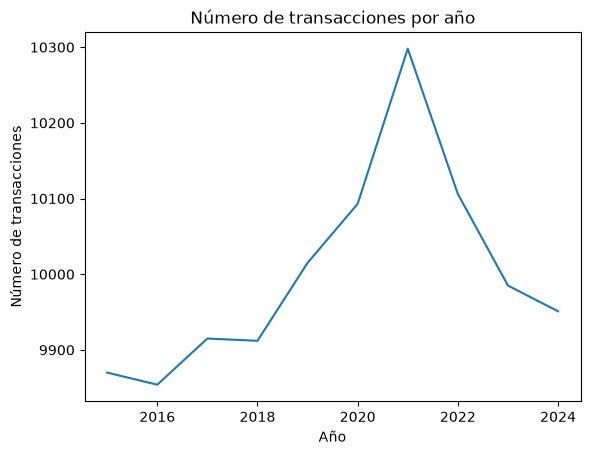

In [11]:
anios_ordenados_crono.plot()

plt.title("Número de transacciones por año")
plt.xlabel("Año")
plt.ylabel("Número de transacciones")

plt.show()


Mi interpretación:

Al analizar la evolución de la cantidad de transacciones, se observa una tendencia general al aumento entre 2016, con algo menos de 9.900 transacciones, y 2021, cuando se alcanza el máximo de casi 10.300, aunque hay pequeñas fluctuaciones durante ese periodo.

A partir de 2021 se produce un descenso gradual hasta 2024, con una cifra entre 9.900 y 10.000 transacciones. En conjunto, el volumen anual se mantiene relativamente estable, alrededor de las 10.000 transacciones.

Visualización e interpretación de la IA (GitHub Copilot):


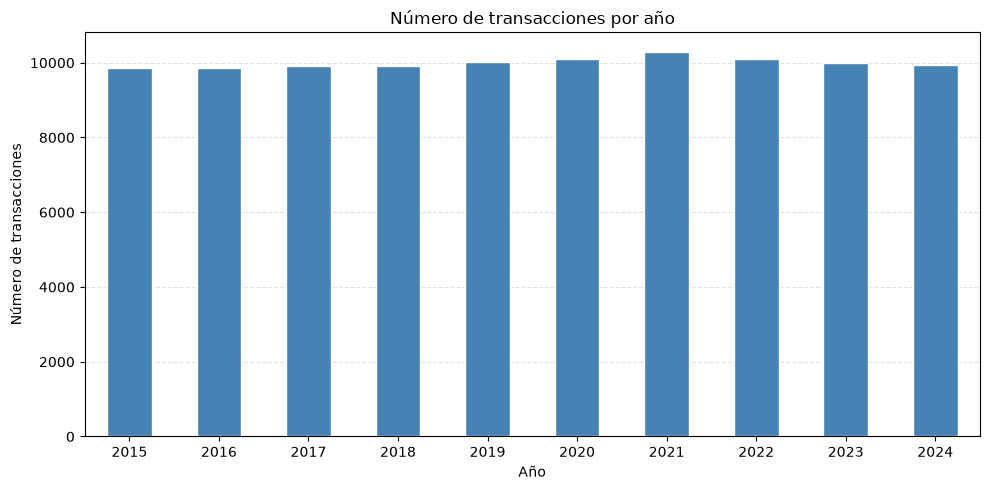

In [12]:
ax = anios_ordenados_crono.plot(
    kind="bar",
    figsize=(10, 5),
    color="steelblue",
    edgecolor="white"
)

ax.set_title("Número de transacciones por año")
ax.set_xlabel("Año")
ax.set_ylabel("Número de transacciones")
ax.set_ylim(0, anios_ordenados_crono.max() * 1.05)
ax.tick_params(axis="x", rotation=0)
ax.set_axisbelow(True)
ax.grid(axis="y", linestyle="--", alpha=0.35)

plt.tight_layout()
plt.show()

La IA propuso un gráfico de barras con el eje vertical desde cero. Esta escala permite apreciar que el volumen de transacciones es similar entre años, aunque dificulta distinguir las pequeñas variaciones anuales. 

Para explorar cómo cambia su percepción visual, se le pedirá una segunda versión con el eje ajustado al rango de los datos, teniendo en cuenta que este recorte puede exagerar las diferencias en un gráfico de barras.

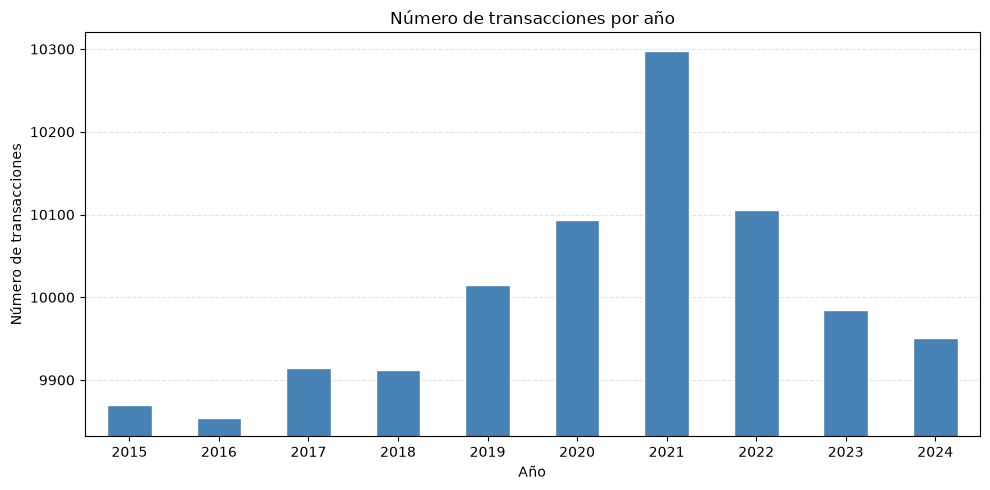

In [13]:
minimo = anios_ordenados_crono.min()
maximo = anios_ordenados_crono.max()
margen = (maximo - minimo) * 0.05

ax = anios_ordenados_crono.plot(
    kind="bar",
    figsize=(10, 5),
    color="steelblue",
    edgecolor="white"
)

ax.set_title("Número de transacciones por año")
ax.set_xlabel("Año")
ax.set_ylabel("Número de transacciones")
ax.set_ylim(minimo - margen, maximo + margen)
ax.tick_params(axis="x", rotation=0)
ax.set_axisbelow(True)
ax.grid(axis="y", linestyle="--", alpha=0.35)

plt.tight_layout()
plt.show()

Conclusión final:

Aunque en este último gráfico se aprecian mejor las variaciones de las transacciones por año, el ajuste del eje vertical hace que las diferencias parezcan más pronunciadas de lo que realmente son. En conjunto, el volumen anual se mantiene relativamente estable, alrededor de las 10.000 transacciones.

Por ello, prefiero el gráfico de líneas para mostrar la evolución temporal, teniendo en cuenta que su escala también resalta pequeñas variaciones.

**Pregunta 2. Encontrar qué usuarios generan mayor volumen de facturación.**

a. Identificar la columna que representa al usuario.

In [14]:
df_transactions.columns

Index(['id', 'card_id', 'business_id', 'timestamp', 'amount', 'declined',
       'product_ids', 'user_id', 'lat', 'longitude', 'discount_amount',
       'tax_amount', 'shipping_amount', 'channel', 'campaign_id',
       'device_type', 'is_international', 'decline_reason', 'distance_km'],
      dtype='str')

La columna es user_id

b. Agrupar las transacciones por usuario y calcular el volumen total de facturación sumando la columna "amount".

In [15]:
transacciones_por_usuario = df_transactions.groupby("user_id")["amount"].sum()

transacciones_por_usuario

user_id
1        8146.82
2        8499.33
3        9338.36
4        8023.33
5       11364.69
          ...   
4996     5712.60
4997     5930.18
4998     6696.73
4999     2911.27
5000     8373.51
Name: amount, Length: 5000, dtype: float64

c. Ordenar los usuarios de mayor a menor volumen de facturación.

In [16]:
transacciones_por_usuario.sort_values(ascending=False) 

user_id
289     47332.90
318     47133.55
455     41396.68
417     37393.91
185     34576.49
          ...   
3652     1432.29
1306     1421.15
1995     1405.70
3119     1327.53
621      1237.00
Name: amount, Length: 5000, dtype: float64

d. Selecciona los N usuarios principales (por ejemplo, los 15 primeros)

In [17]:
top_15_usuarios =transacciones_por_usuario.sort_values(ascending=False).head(15)

top_15_usuarios

user_id
289    47332.90
318    47133.55
455    41396.68
417    37393.91
185    34576.49
285    33383.56
454    29528.42
349    27835.38
193    27462.59
317    22484.76
388    21313.31
443    20605.24
319    20455.52
393    19632.36
437    18518.81
Name: amount, dtype: float64

e. Representa el resultado mediante un gráfico de barras utilizando Seaborn.

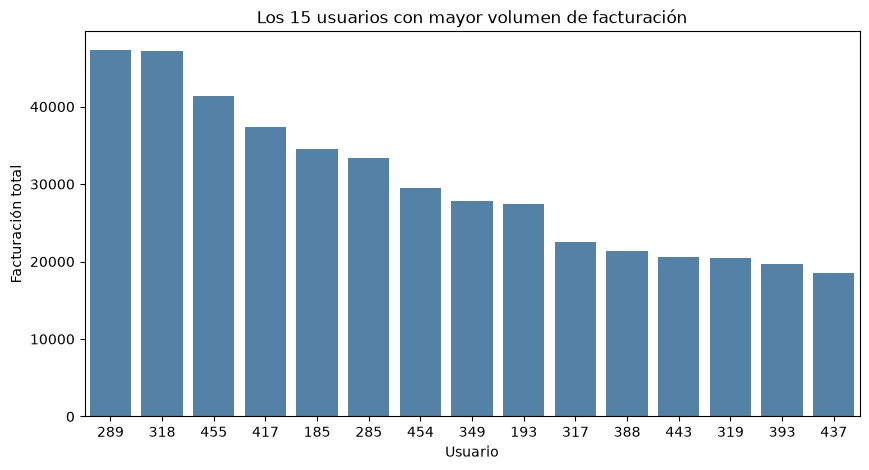

In [18]:
plt.figure(figsize=(10,5))

sns.barplot(
    x=top_15_usuarios.index.astype(str),
    y=top_15_usuarios.values,
    color="steelblue",
    errorbar=None)

plt.title("Los 15 usuarios con mayor volumen de facturación")
plt.xlabel("Usuario")
plt.ylabel("Facturación total")

plt.show()

Mi interpretación:

Este gráfico de barras permite comparar la facturación total de los 15 usuarios con mayores importes acumulado. El usuario 289 ocupa el primer lugar, con 47332,90, seguido del usuario 318, con 47133,55. La diferencia entre ambos es pequeña: 199,35.

A partir del tercer usuario, se observa una disminución más marcada de los importes dentro de este grupo de 15.

Visualización e interpretación de la IA (GitHub Copilot):

Una alternativa es un gráfico tipo lollipop horizontal. Representa los mismos 15 usuarios y sus importes, pero con un punto al final de una línea en vez de una barra sólida. La orientación horizontal deja más espacio para los nombres de usuario; la línea y el punto hacen que los valores sean fáciles de comparar. Como limitación, las barras suelen transmitir mejor el tamaño de cada importe de un vistazo.

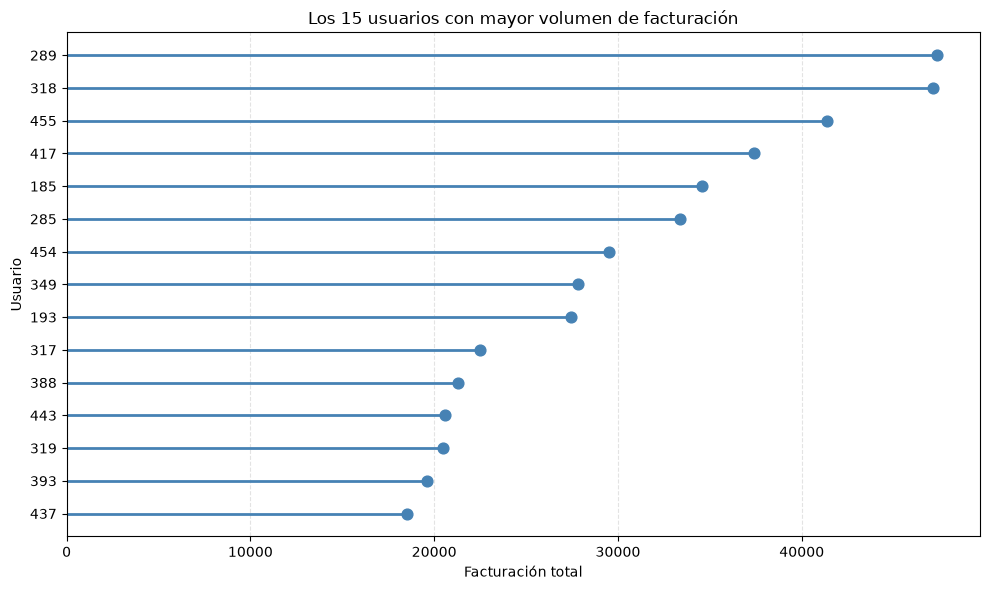

In [19]:
# Reordena los mismos 15 usuarios para que el importe mayor quede arriba.
datos = top_15_usuarios.sort_values(ascending=True)
posiciones = range(len(datos))

fig, ax = plt.subplots(figsize=(10, 6))

ax.hlines(
    y=posiciones,
    xmin=0,
    xmax=datos.values,
    color="steelblue",
    linewidth=2
)
ax.scatter(datos.values, posiciones, color="steelblue", s=60, zorder=3)

ax.set_yticks(posiciones)
ax.set_yticklabels(datos.index.astype(str))
ax.set_xlim(left=0)
ax.set_title("Los 15 usuarios con mayor volumen de facturación")
ax.set_xlabel("Facturación total")
ax.set_ylabel("Usuario")
ax.grid(axis="x", linestyle="--", alpha=0.35)
ax.set_axisbelow(True)

plt.tight_layout()
plt.show()

Conclusión final:

Al comparar ambos gráficos, me inclino por el de barras. Aunque los puntos al final de cada línea del gráfico lollipop propuesto por la IA ayudan a identificar el importe de cada usuario, considero que las barras permiten apreciar más rápidamente, de un solo vistazo, la magnitud de los importes y las diferencias entre usuarios.

**Pregunta 3. Confirmar si existen diferencias en la distribución del importe de las transacciones según la hora del día y si han sido aceptadas o rechazadas.**

a. Crear una nueva columna con la hora del día a partir del timestamp.

In [20]:
hora = columna_temporal.dt.hour

df_transactions["hora_transaccion"] = hora

display(df_transactions["hora_transaccion"].head())

0     7
1    15
2    19
3    18
4     4
Name: hora_transaccion, dtype: int32

b. Utiliza un violinplot de seaborn para analizar la distribución de los importes.


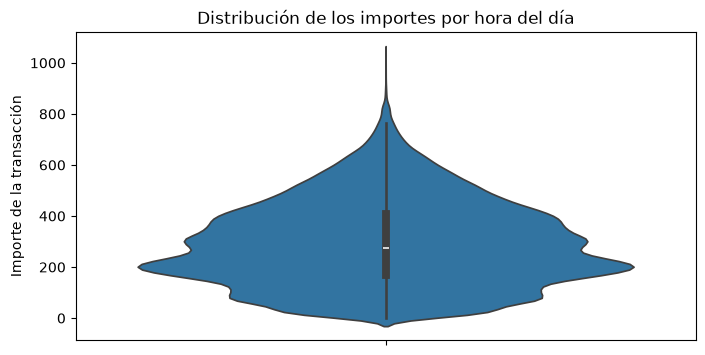

In [21]:
plt.figure(figsize=(8,4))

sns.violinplot(
    data=df_transactions,
    y="amount"
)

plt.title("Distribución de los importes por hora del día")
plt.ylabel("Importe de la transacción")

plt.show()

c. Asigna: "x" por la hora del día, "y" por el importe de la transacción y "hue" por el estado de la transacción.

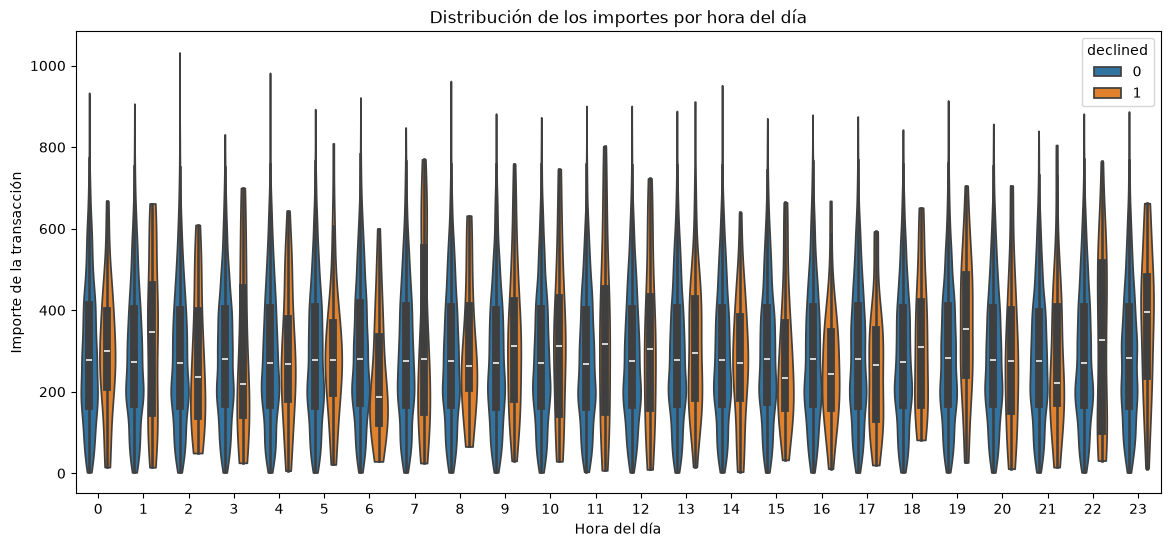

In [22]:
plt.figure(figsize=(14,6))

sns.violinplot(
    data=df_transactions,
    x="hora_transaccion",
    y="amount",
    hue="declined",
    cut=0
)

plt.title("Distribución de los importes por hora del día")
plt.xlabel("Hora del día")
plt.ylabel("Importe de la transacción")

plt.show()

d. Activa split para comparar aceptadas y rechazadas e inner con quartile para mostrar mediana y cuartiles.

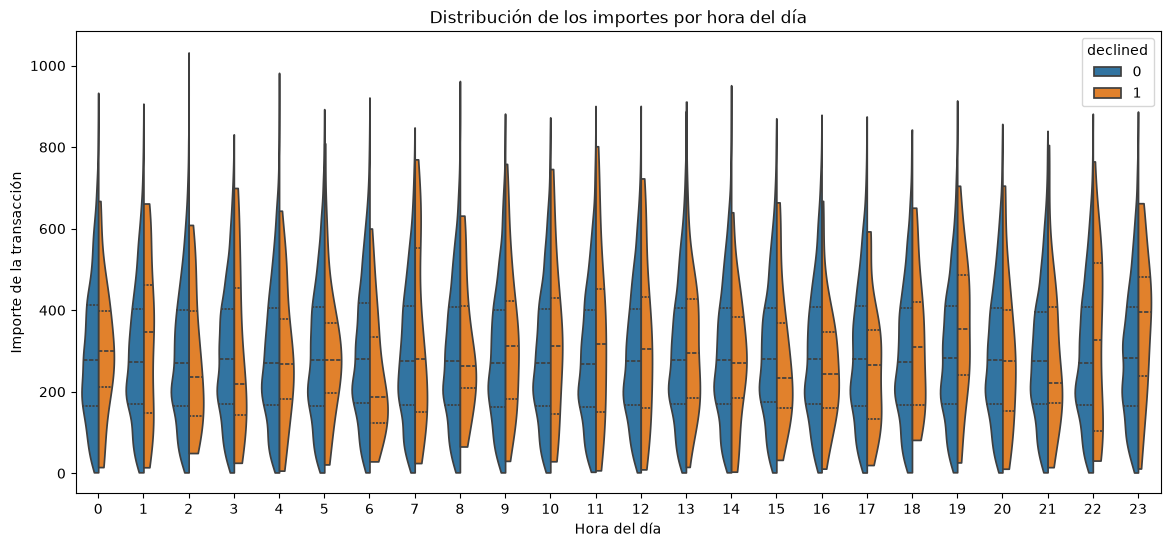

In [23]:
plt.figure(figsize=(14,6))

sns.violinplot(
    data=df_transactions,
    x="hora_transaccion",
    y="amount",
    hue="declined",
    cut=0,
    split=True,
    inner="quartile"
)

plt.title("Distribución de los importes por hora del día")
plt.xlabel("Hora del día")
plt.ylabel("Importe de la transacción")

plt.show()

Mi interpretación:

Sí se observan diferencias en la distribución de los importes según la hora del día y si las transacciones han sido aceptadas o rechazadas. 

El violinplot permite comparar la concentración de los importes, sus medianas y cuartiles en cada grupo.



Visualización e interpretación de la IA (GitHub Copilot):

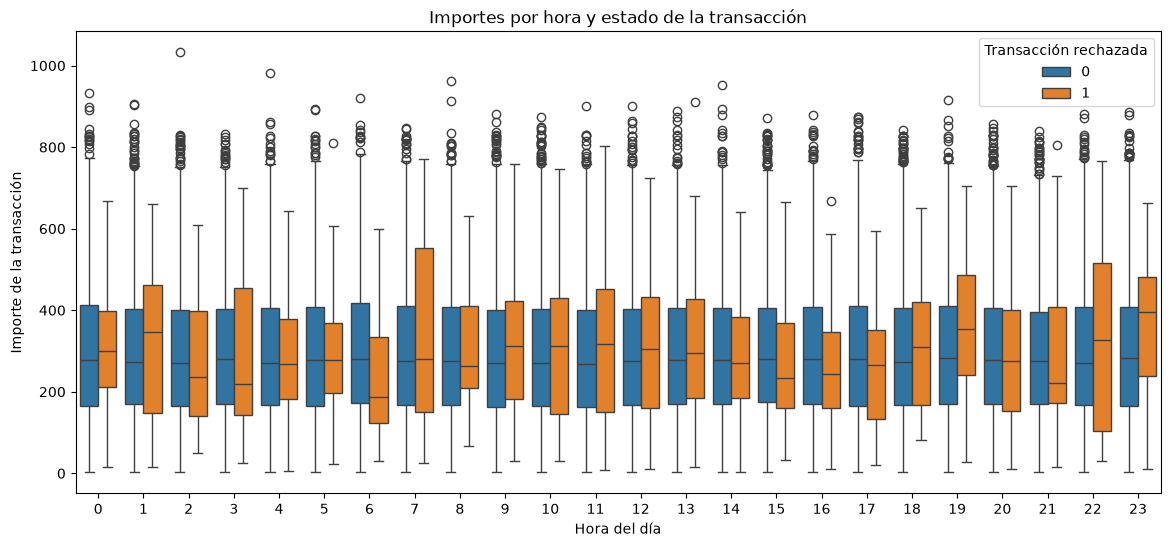

In [24]:
plt.figure(figsize=(14, 6))

sns.boxplot(
    data=df_transactions,
    x="hora_transaccion",
    y="amount",
    hue="declined",
    dodge=True
)

plt.title("Importes por hora y estado de la transacción")
plt.xlabel("Hora del día")
plt.ylabel("Importe de la transacción")
plt.legend(title="Transacción rechazada")

plt.show()

Una alternativa más compacta y fácil de comparar es un boxplot agrupado: cada hora muestra dos cajas, una por estado de la transacción.

El boxplot facilita comparar la mediana y el rango intercuartílico (el 50 % central) entre estados y horas. También señala valores atípicos; por defecto, sus bigotes llegan hasta 1,5 veces el rango intercuartílico, no necesariamente hasta los valores mínimo y máximo.

Frente al violín, se pierde la forma de la distribución: el boxplot no muestra dónde se concentra más la densidad ni permite apreciar con la misma facilidad si hay varios picos. A cambio, sus resúmenes suelen hacer más directa la comparación entre grupos.



Conclusión final:

Prefiero el violinplot porque me permite apreciar con mayor claridad cómo se distribuyen los importes en cada hora. Las zonas más anchas muestran dónde se concentran los importes y, al dividir cada violín por colores, puedo comparar las transacciones aceptadas y rechazadas de una misma hora.

Aunque el boxplot facilita comparar medianas, cuartiles y valores atípicos, en este caso me resulta más intuitivo el violinplot para interpretar la distribución de ambos grupos.

En cuanto a los datos en el gráfico violinplot, los importes de las transacciones aceptadas presentan una distribución bastante similar entre horas, mientras que los de las rechazadas muestran mayores variaciones entre horas. Las medianas de las rechazadas están por encima de las aceptadas en algunas horas y por debajo en otras. Estas diferencias pueden orientar una investigación más detallada, pero el gráfico por sí solo no permite determinar sus causas ni justificar cambios en las reglas de aceptación. Para ello, sería necesario analizar también la cantidad de operaciones, los motivos de rechazo, y comprobar si el patrón se repite en distintos días.

**Pregunta 4. En qué dias de la semana se concentra más actividad de venta.**

In [25]:
df_ventas = df_transactions[df_transactions["declined"]==0]

df_ventas["dia_transacciones"] = df_ventas["timestamp"].dt.dayofweek

ventas_por_dia = df_ventas["dia_transacciones"].value_counts().sort_index()

display(ventas_por_dia)

dia_transacciones
0    13996
1    14045
2    14152
3    14388
4    14138
5    14221
6    14171
Name: count, dtype: int64

El jueves (número 3) registra la mayor actividad y el lunes(número 0) la menor, aunque las cantidades son bastante similares: la diferencia entre ambos es de 392 ventas.


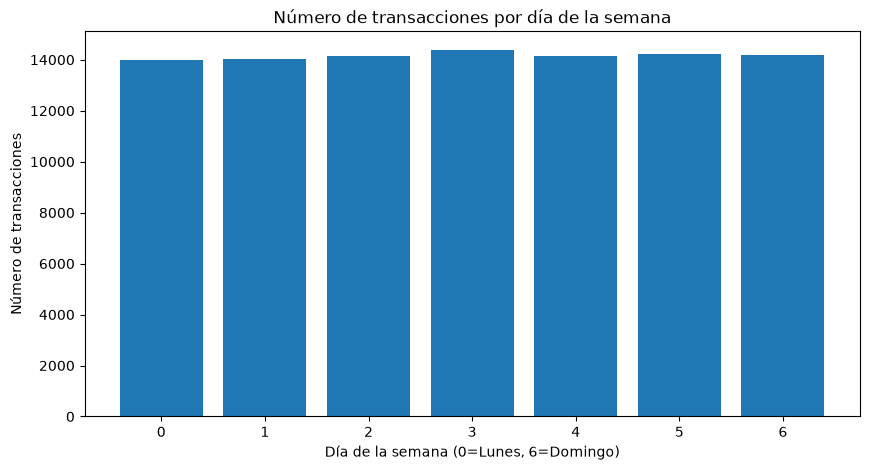

In [26]:
plt.figure(figsize=(10,5))

plt.bar(
    ventas_por_dia.index,
    ventas_por_dia.values
)

plt.title("Número de transacciones por día de la semana")
plt.xlabel("Día de la semana (0=Lunes, 6=Domingo)")
plt.ylabel("Número de transacciones")

plt.show()

Visualización de la IA



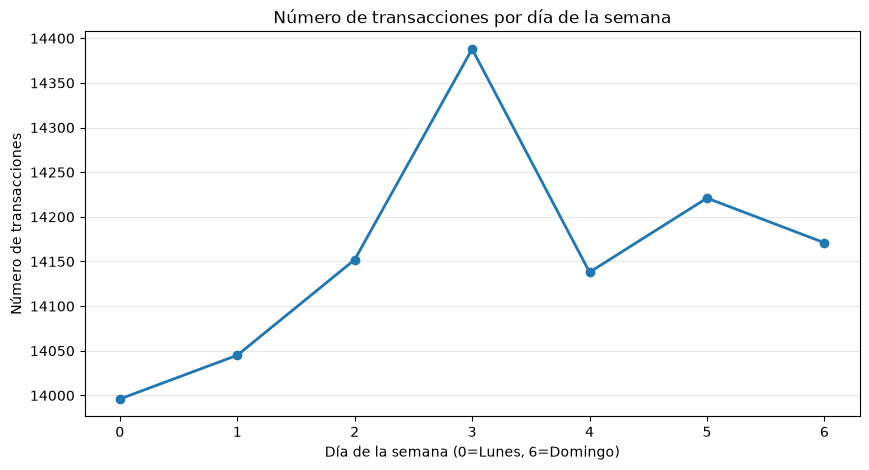

In [27]:
plt.figure(figsize=(10, 5))

plt.plot(
    ventas_por_dia.index,
    ventas_por_dia.values,
    marker="o",
    linewidth=2
)

plt.title("Número de transacciones por día de la semana")
plt.xlabel("Día de la semana (0=Lunes, 6=Domingo)")
plt.ylabel("Número de transacciones")
plt.xticks(ventas_por_dia.index)
plt.grid(axis="y", alpha=0.3)

plt.show()

La IA propuso como alternativa un gráfico de líneas con el eje vertical ajustado al rango de los datos. Esto permite apreciar mejor las diferencias entre los días, aunque visualmente pueden parecer más grandes de lo que son en proporción al total de ventas.

Conclusión final:

El gráfico de líneas con el eje vertical ajustado permite distinguir mejor las pequeñas diferencias entre días, aunque estas pueden parecer visualmente más pronunciadas. También podría resultar útil para representar la evolución de las ventas durante una semana específica, filtrando previamente los datos.

Para esta comparación por días de la semana, prefiero el gráfico de barras. Aunque ajustar su eje permitiría destacar las diferencias, mantendría el inicio en cero y añadiría las cifras sobre cada barra para mostrar que la actividad es bastante similar entre días.

## Ejercicio 2: Preguntas analíticas complejas (con guía)

🌍 **Contexto:** Este ejercicio requiere combinar información de varias tablas del modelo para responder correctamente a las preguntas.

Aquí sí será necesario:

- Hacer `merge` entre tablas.
- Utilizar `groupby`, `pivot_table`, `crosstab`…
- Aplicar agregaciones, transformaciones intermedias y funciones.

#### 1. ¿Dependemos excesivamente de un número reducido de países de las compañías vendedoras?

**Pasos orientativos:**

1. Combinar la información de transacciones con la de compañías.
2. Agrupar la facturación por país.
3. Calcular la facturación total generada por cada país.
4. Ordenar los países de mayor a menor facturación.
5. Calcular el porcentaje acumulado sobre el total.
6. Visualizar.

#### 2. ¿Existe estacionalidad en las ventas?

**Pasos orientativos:**

1. Trabajar con las fechas de las transacciones.
2. Extraer la información temporal relevante: año y mes.
3. Calcular el volumen total de ventas —suma de `amount`— por año y mes.
4. Comparar patrones temporales entre años. Crear una tabla de tipo pivote.
5. Visualizar la evolución.

#### 3. Análisis de concentración y variabilidad: elige UNA opción

**Opción A – Producto (solo si dispones de la tabla de productos)**

**¿Qué productos generan más ingresos y con qué variabilidad?**

Pasos orientativos:

1. Combinar transacciones, la tabla puente y productos.
2. Calcular los ingresos por producto utilizando `groupby`, `sum` y `sort`.
3. Seleccionar los N productos principales: por ejemplo, los 15 primeros.
4. Escoger una visualización adecuada para analizar la dispersión.

**Opción B – Actividad de usuarios (alternativa si no dispones de la tabla de productos)**

**¿Hay usuarios que han dejado de comprar recientemente?**

Pasos orientativos:

1. Identificar la última compra de cada usuario.
2. Calcular el tiempo transcurrido desde la última compra.
3. Visualizar la distribución del tiempo transcurrido desde la última compra.

#### 4. ¿Cómo varía la actividad de venta por franjas horarias a lo largo de los años? (Patrones horarios)

**Pasos orientativos:**

1. Crear franjas horarias a partir de la hora: crear una función y aplicarla utilizando `apply`.
2. Construir una tabla agregada utilizando `crosstab`.
3. Visualizar mediante un mapa de calor (`heatmap`).

👉 **Para cada pregunta:**

- Describir brevemente los pasos seguidos.
- Mostrar la visualización final.
- Interpretar qué implica para el negocio.

**PASO A PASO**

#### Pregunta 1. ¿Dependemos excesivamente de un número reducido de países de las compañías vendedoras?

**Pasos orientativos:**

Paso 1. Combinar la información de transacciones con la de compañías.


In [28]:
display(df_ventas.columns)

Index(['id', 'card_id', 'business_id', 'timestamp', 'amount', 'declined',
       'product_ids', 'user_id', 'lat', 'longitude', 'discount_amount',
       'tax_amount', 'shipping_amount', 'channel', 'campaign_id',
       'device_type', 'is_international', 'decline_reason', 'distance_km',
       'hora_transaccion', 'dia_transacciones'],
      dtype='str')

In [29]:
pd.read_sql("SHOW TABLES FROM sprint2_estrella", engine)

,Tables_in_sprint2_estrella
0,companies
1,credit_cards
2,estado_tarjetas
3,products
4,transaction_products
5,transactions
6,users
7,vistamarketing


In [30]:
df_companies = pd.read_sql(
    "SELECT * FROM companies", engine)

print(df_companies.shape)
display(df_companies.head())


(100, 8)


,company_id,company_name,phone,email,country,website,merchant_category,merchant_price_position
0,b-2222,Ac Fermentum Incorporated,+64 601 244 6320,donec.porttitor.tellus@yahoo.net,Germany,https://www.ac-fermentum-incorporated.com,Beauty,mid-market
1,b-2226,Magna A Neque Industries,+33 823 560 3779,risus.donec.nibh@icloud.org,Australia,https://www.magna-a-neque-industries.com,Travel,budget
2,b-2230,Fusce Corp.,+29 657 646 4324,risus@protonmail.edu,United States,https://www.fusce-corp.com,Home,mid-market
3,b-2234,Convallis In Incorporated,+6 693 982 1255,mauris.ut@aol.couk,Germany,https://www.convallis-in-incorporated.com,Sports,mid-market
4,b-2238,Ante Iaculis Nec Foundation,+69 914 549 1009,sed.dictum.proin@outlook.ca,New Zealand,https://www.ante-iaculis-nec-foundation.com,Toys,mid-market


A cotinuación se realiza la combinación de ambos dataframes con merge(). 

La instrucción how=left indica una unión por la izquierda: conserva todas las filas de df_ventas y añade la información de las compañías que coincidan. Si una venta no encuentra compañía, los campos añadidos quedan como NaN.

In [31]:
df_ventas_companies = pd.merge(
    df_ventas,
    df_companies,
    how="left",
    left_on="business_id",
    right_on="company_id"   
)

In [32]:
df_ventas_companies.columns

Index(['id', 'card_id', 'business_id', 'timestamp', 'amount', 'declined',
       'product_ids', 'user_id', 'lat', 'longitude', 'discount_amount',
       'tax_amount', 'shipping_amount', 'channel', 'campaign_id',
       'device_type', 'is_international', 'decline_reason', 'distance_km',
       'hora_transaccion', 'dia_transacciones', 'company_id', 'company_name',
       'phone', 'email', 'country', 'website', 'merchant_category',
       'merchant_price_position'],
      dtype='str')

In [33]:
display(df_ventas_companies.head())

,id,card_id,business_id,timestamp,amount,declined,product_ids,user_id,lat,longitude,...,hora_transaccion,dia_transacciones,company_id,company_name,phone,email,country,website,merchant_category,merchant_price_position
0,00043A49-2949-494B-A5DD-A5BAE3BB19DD,CcS-9294,b-2458,2024-08-28 07:16:46,433.51,0,"16, 26, 97, 87",4713,46.199929,1.435540,...,7,2,b-2458,Eget Tincidunt Dui Institute,+18 210 327 5206,eget.laoreet@hotmail.org,Netherlands,https://www.eget-tincidunt-dui-institute.com,Toys,mid-market
1,00045D6B-ED2E-4F2F-8186-CEE074D875D0,CcS-6699,b-2390,2020-07-14 15:37:45,332.38,0,"30, 11, 16, 81",2118,29.757296,-95.379637,...,15,1,b-2390,Neque Tellus Imperdiet Corp.,+12 445 145 3593,vestibulum.ante.ipsum@aol.edu,Ireland,https://www.neque-tellus-imperdiet-corp.com,Food,budget
2,000481C3-1C26-4FEF-83A0-4CD0EB004BBD,CcS-6696,b-2230,2017-09-04 19:44:53,175.00,0,72,2115,53.548884,-113.503053,...,19,0,b-2230,Fusce Corp.,+29 657 646 4324,risus@protonmail.edu,United States,https://www.fusce-corp.com,Home,mid-market
3,00051AA4-9CBE-4268-B070-C38062A1B3E2,CcS-7606,b-2266,2017-01-05 18:19:25,158.55,0,18,3025,52.208370,5.690806,...,18,3,b-2266,Mus Aenean Eget Foundation,+1 504 922 3000,mi.duis@hotmail.net,Sweden,https://www.mus-aenean-eget-foundation.com,Sports,mid-market
4,0008A312-EDFE-4A4F-BC99-E9C92EC3CA4D,CcU-3358,b-2598,2023-09-23 04:51:43,317.97,0,"35, 33, 19",215,53.553486,-113.499134,...,4,5,b-2598,Aliquam Iaculis Lacus Corp.,+23 674 242 3712,dictum@aol.org,Belgium,https://www.aliquam-iaculis-lacus-corp.com,Fashion,budget


Paso 2. Agrupar la facturación por país.

In [34]:
df_ventas_companies.groupby("country")["amount"]

Paso 3. Calcular la facturación total generada por cada país.

In [35]:
facturacion_por_pais = df_ventas_companies.groupby("country")["amount"].sum()

Paso 4. Ordenar los países de mayor a menor facturación.



In [36]:
facturacion_por_pais_ordenada = facturacion_por_pais.sort_values(ascending=False)

print(facturacion_por_pais_ordenada)

country
Sweden            4884077.83
Netherlands       4470873.59
United Kingdom    4065098.37
Italy             4061060.93
Germany           3984664.03
France            1406668.15
United States     1085266.88
Belgium            937789.26
Norway             798331.87
Ireland            707379.30
New Zealand        696403.99
Australia          687532.20
Canada             552067.53
Spain              452574.16
China              235421.76
Name: amount, dtype: float64


Paso 5. Calcular el porcentaje acumulado sobre el total.


In [37]:
facturacion_total = facturacion_por_pais_ordenada.sum()

porcentaje_pais_individual = ((facturacion_por_pais_ordenada / facturacion_total) * 100)

#sumar progresivamente los porcentajes de cada país para obtener el porcentaje acumulado
porcentaje_acumulado = porcentaje_pais_individual.cumsum()

display(porcentaje_acumulado.round(2))

country
Sweden             16.83
Netherlands        32.23
United Kingdom     46.24
Italy              60.23
Germany            73.96
France             78.80
United States      82.54
Belgium            85.77
Norway             88.52
Ireland            90.96
New Zealand        93.36
Australia          95.73
Canada             97.63
Spain              99.19
China             100.00
Name: amount, dtype: float64

Paso 6. Visualizar.

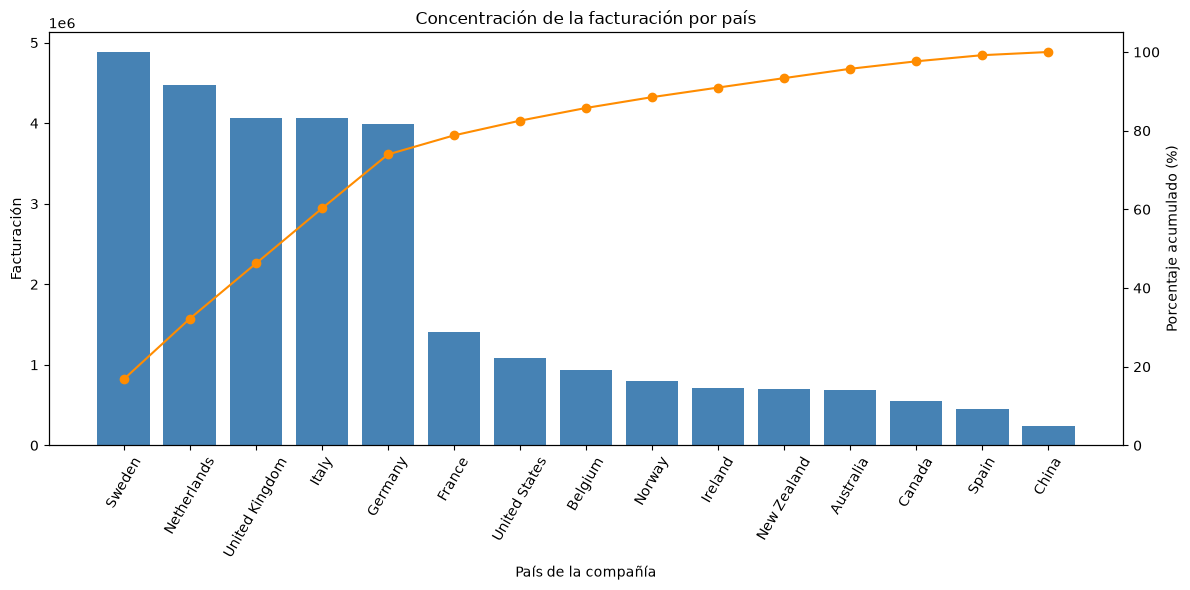

In [38]:
fig, ax1 = plt.subplots(figsize=(12, 6))

# Barras: facturación de cada país
ax1.bar(
    facturacion_por_pais_ordenada.index,
    facturacion_por_pais_ordenada.values,
    color="steelblue"
)

ax1.set_xlabel("País de la compañía")
ax1.set_ylabel("Facturación")
ax1.tick_params(axis="x", rotation=60)

# Segundo eje vertical, compartiendo los mismos países
ax2 = ax1.twinx()

# Línea: porcentaje acumulado
ax2.plot(
    porcentaje_acumulado.index,
    porcentaje_acumulado.values,
    color="darkorange",
    marker="o"
)

ax2.set_ylabel("Porcentaje acumulado (%)")
ax2.set_ylim(0, 105)

plt.title("Concentración de la facturación por país")
fig.tight_layout()
plt.show()

#### ¿Qué  implica para el negocio?

El gráfico de Pareto muestra que 5 de los 15 países -Suecia, Países Bajos, Reino Unido, Italia y Alemania- concentran aproximadamente el 74% de la facturación. Por tanto, el negocio depende de gran medida de las ventas de las compañías ubicadas en dichos países.

Esta concentración supone un riesgo: una disminución de sus ventas podría afectar considerablemente a la facturación total. Conviene cuidar las relaciones con estas compañías y evaluar oportunidades para aumentar la participación de otros países.

Finalmente, se observa una dependencia importante del negocio respecto a las compañías vendedoras de esos cinco países. Sin embargo, con este análisis no podemos determinar si dicha dependencia es excesiva. Para valorarlo, sería necesario conocer los objetivos del negocio y cuánto riesgo está dispuesto a asumir.

#### Pregunta 2. ¿Existe estacionalidad en las ventas?

**Pasos orientativos:**

1. Trabajar con las fechas de las transacciones.
2. Extraer la información temporal relevante: año y mes.
3. Calcular el volumen total de ventas —suma de `amount`— por año y mes.
4. Comparar patrones temporales entre años. Crear una tabla de tipo pivote.
5. Visualizar la evolución.

PASO A PASO

Paso 1. Trabajar con las fechas de las transacciones.

In [39]:
display(df_ventas["timestamp"].head())

0   2024-08-28 07:16:46
1   2020-07-14 15:37:45
2   2017-09-04 19:44:53
3   2017-01-05 18:19:25
4   2023-09-23 04:51:43
Name: timestamp, dtype: datetime64[us]

Paso 2. Extraer la información temporal relevante: año y mes.

In [40]:
df_ventas["anio"] = df_ventas["timestamp"].dt.year
df_ventas["mes"] = df_ventas["timestamp"].dt.month


Paso 3. Calcular el volumen total de ventas —suma de `amount`— por año y mes.

In [41]:
total_ventas_por_anio_mes = df_ventas.groupby(["anio", "mes"])["amount"].sum()

display(total_ventas_por_anio_mes.head(12))

anio  mes
2015  1      221978.21
      2      245780.13
      3      253000.65
      4      245597.21
      5      248585.36
      6      232624.35
      7      241252.27
      8      233797.97
      9      227211.93
      10     241722.74
      11     225568.41
      12     234787.51
Name: amount, dtype: float64

Paso 4. Comparar patrones temporales entre años. Crear una tabla de tipo pivote.

In [42]:
tabla_pivote = df_ventas.pivot_table(
    index="mes",
    columns="anio",
    values="amount",
    aggfunc="sum"
)

display(tabla_pivote)

anio,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024
mes,,,,,,,,,,
1,221978.21,224451.27,222956.21,227411.90,222944.11,231702.95,243339.85,224709.53,228413.66,226393.73
2,245780.13,248112.42,252303.71,245092.09,259807.32,248318.04,257434.31,235427.85,251422.67,249898.07
3,253000.65,246634.37,237621.09,237099.83,276818.21,258872.56,250861.14,271978.12,241711.00,245792.02
4,245597.21,240833.04,251596.72,234246.30,242707.81,244251.90,259770.51,237165.49,241264.06,244769.15
5,248585.36,241306.84,240125.80,244448.97,242550.42,253699.74,239662.08,276262.60,261355.45,254122.62
6,232624.35,230577.43,240337.61,242769.22,241694.85,236410.96,234080.71,260082.37,232254.56,244370.81
7,241252.27,237081.73,240576.35,231261.73,233513.25,240255.64,251450.91,233349.01,238652.72,230031.53
8,233797.97,235600.88,230225.76,228759.89,237070.53,232658.86,237051.75,245198.95,237981.15,236671.63
9,227211.93,241530.84,230606.28,236768.38,232551.83,257964.96,245398.37,254316.72,234226.30,234226.89


Paso 5. Visualizar la evolución

Reorganizo la tabla pivote en una serie ordenada por año y mes para representar la evolución cronológica de la facturación mensual mediante una única línea.

In [43]:
ventas_mensuales = tabla_pivote.T.stack().sort_index()

display(ventas_mensuales.head())

anio  mes
2015  1      221978.21
      2      245780.13
      3      253000.65
      4      245597.21
      5      248585.36
dtype: float64

.T intercambia filas y columnas: los años pasan a las filas.

.stack() coloca los meses de cada año debajo de él, formando una única Serie.

.sort_index() ordena primero por año y después por mes.

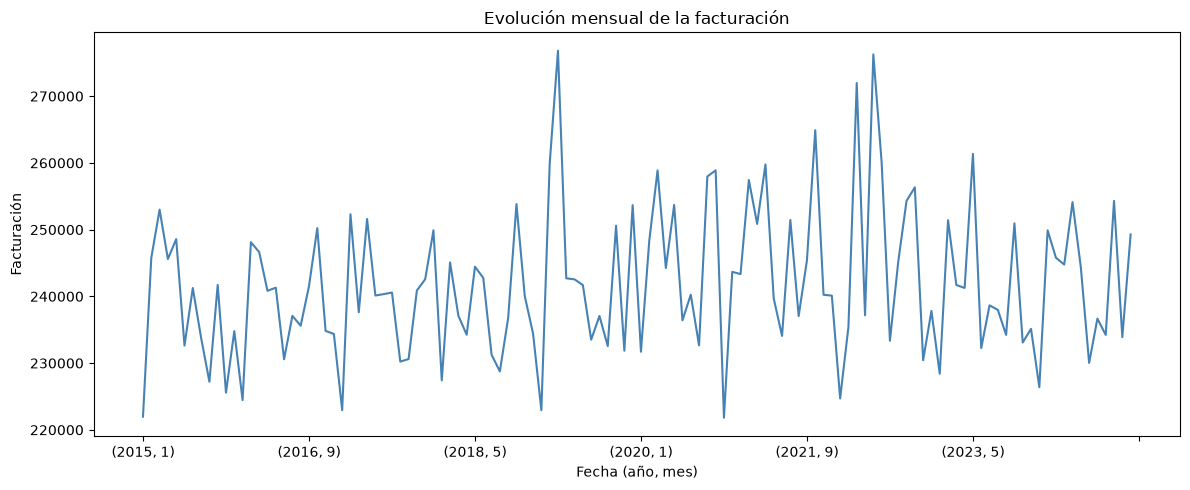

In [44]:
ventas_mensuales.plot(
    kind="line",
    figsize=(12,5),
    color="steelblue"
)

plt.title("Evolución mensual de la facturación")
plt.xlabel("Fecha (año, mes)")
plt.ylabel("Facturación")
plt.tight_layout()

plt.show()

La facturación mensual presenta subidas y bajadas, pero no se observa una tendencia sostenida de crecimiento o descenso durante el período analizado. La mayoría de los meses se sitúa aproximadamente entre 220.000 y 260.000, con algunos picos superiores a 270.000.

Para el negocio, esto sugiere una facturación relativamente estable a largo plazo, aunque con variaciones mensuales que conviene considerar al planificar ingresos y gastos. 

Por otro lado, en este gráfico no se ve claramente si las ventas siguen un patrón que se repite cada año (estacionalidad). Para comprobarlo, podríamos mirar, por ejemplo, si octubre suele tener más ventas y enero menos en distintos años.

También sería útil saber si en los meses de mayor facturación se hacen más compras o si cada compra tiene un importe mayor. Además, como unos meses tienen más días que otros, convendría calcular cuánto se factura por día para compararlos de forma más justa.

#### Pregunta 3. Análisis de concentración y variabilidad: elige UNA opción

**Opción A – Producto (solo si dispones de la tabla de productos)**

**¿Qué productos generan más ingresos y con qué variabilidad?**

Pasos orientativos:

1. Combinar transacciones, la tabla puente y productos.
2. Calcular los ingresos por producto utilizando `groupby`, `sum` y `sort`.
3. Seleccionar los N productos principales: por ejemplo, los 15 primeros.
4. Escoger una visualización adecuada para analizar la dispersión.


Paso 1. Combinar transacciones, la tabla puente y productos.

In [45]:
df_products = pd.read_sql(
    "SELECT * FROM products", engine)

df_transaction_products = pd.read_sql(
    "SELECT * FROM transaction_products",engine)

In [46]:
display(df_products.head())
display(df_transaction_products.head())

,id,product_name,price,colour,weight,warehouse_id,category,brand,cost,launch_date
0,1,Direwolf Stannis,161.11,#7c7c7c,1.0,WH-4,Sports,Runway Pro,63.84,2014-11-01
1,2,Tarly Stark,9.24,#919191,2.0,WH-3,Gaming,Questbyte,4.74,2013-02-07
2,3,duel tourney Lannister,171.13,#d8d8d8,1.5,WH-2,Food,Daily Pantry,107.07,2013-08-18
3,4,warden south duel,71.89,#111111,3.0,WH-1,Books,NorthPress,39.17,2013-12-31
4,5,skywalker ewok,171.22,#dbdbdb,3.2,WH-0,Home,NordHaus,83.69,2014-07-17


,transaction_id,product_id
0,001A60EA-DC9C-4E5A-9460-6628B100E7E1,1
1,0032F0BB-BBE6-4AA5-B5EE-EEAD533C0C48,1
2,00342381-503D-422D-85AB-F2D4FFAAD4C7,1
3,004C0A80-E537-46D8-BE44-343D2176DF15,1
4,004D1DB5-B2CB-4460-98B6-31C42CA96E5F,1


In [47]:
combinadas_productos_puente = pd.merge(
    df_transaction_products,
    df_products,
    how = "left",
    left_on = "product_id",
    right_on = "id")

In [48]:
combinadas_productos_puente.columns

Index(['transaction_id', 'product_id', 'id', 'product_name', 'price', 'colour',
       'weight', 'warehouse_id', 'category', 'brand', 'cost', 'launch_date'],
      dtype='str')

In [49]:
df_ventas.columns

Index(['id', 'card_id', 'business_id', 'timestamp', 'amount', 'declined',
       'product_ids', 'user_id', 'lat', 'longitude', 'discount_amount',
       'tax_amount', 'shipping_amount', 'channel', 'campaign_id',
       'device_type', 'is_international', 'decline_reason', 'distance_km',
       'hora_transaccion', 'dia_transacciones', 'anio', 'mes'],
      dtype='str')

In [50]:
combinadas_ventas_productos = pd.merge(
    df_ventas,
    combinadas_productos_puente,
    how = "inner",
    left_on = "id",
    right_on = "transaction_id",
    suffixes=("_venta", "_producto")
)

In [51]:
combinadas_ventas_productos.columns

Index(['id_venta', 'card_id', 'business_id', 'timestamp', 'amount', 'declined',
       'product_ids', 'user_id', 'lat', 'longitude', 'discount_amount',
       'tax_amount', 'shipping_amount', 'channel', 'campaign_id',
       'device_type', 'is_international', 'decline_reason', 'distance_km',
       'hora_transaccion', 'dia_transacciones', 'anio', 'mes',
       'transaction_id', 'product_id', 'id_producto', 'product_name', 'price',
       'colour', 'weight', 'warehouse_id', 'category', 'brand', 'cost',
       'launch_date'],
      dtype='str')

In [52]:
display(combinadas_ventas_productos.head())

,id_venta,card_id,business_id,timestamp,amount,declined,product_ids,user_id,lat,longitude,...,id_producto,product_name,price,colour,weight,warehouse_id,category,brand,cost,launch_date
0,00043A49-2949-494B-A5DD-A5BAE3BB19DD,CcS-9294,b-2458,2024-08-28 07:16:46,433.51,0,"16, 26, 97, 87",4713,46.199929,1.435540,...,16,the duel warden,180.91,#666666,3.0,WH-11,Home,NordHaus,101.11,2014-05-31
1,00043A49-2949-494B-A5DD-A5BAE3BB19DD,CcS-9294,b-2458,2024-08-28 07:16:46,433.51,0,"16, 26, 97, 87",4713,46.199929,1.435540,...,26,Stark Karstark,53.01,#898989,2.0,WH-21,Food,GreenFork,30.49,2013-02-15
2,00043A49-2949-494B-A5DD-A5BAE3BB19DD,CcS-9294,b-2458,2024-08-28 07:16:46,433.51,0,"16, 26, 97, 87",4713,46.199929,1.435540,...,87,sith Jade,96.26,#e2e2e2,1.5,WH-82,Food,Market&Co,66.36,2013-11-10
3,00043A49-2949-494B-A5DD-A5BAE3BB19DD,CcS-9294,b-2458,2024-08-28 07:16:46,433.51,0,"16, 26, 97, 87",4713,46.199929,1.435540,...,97,jinn Winterfell,65.25,#bababa,1.0,WH-92,Beauty,CareLab,26.25,2013-02-22
4,00045D6B-ED2E-4F2F-8186-CEE074D875D0,CcS-6699,b-2390,2020-07-14 15:37:45,332.38,0,"30, 11, 16, 81",2118,29.757296,-95.379637,...,11,Karstark Dorne,49.70,#141414,2.7,WH-6,Electronics,Nexa,34.45,2014-09-01


Paso 2.  Calcular los ingresos por producto utilizando `groupby`, `sum` y `sort`.

Agrupo las ventas por identificador y nombre del producto, sumo price para calcular sus ingresos totales y ordeno los resultados de mayor a menor. 

Considero que price es el precio cobrado por unidad y que cada fila representa una unidad vendida.

In [53]:
ingresos_por_producto = (
    combinadas_ventas_productos
    .groupby(["product_id", "product_name"])["price"]
    .sum()
    .sort_values(ascending=False)
)

Paso 3. Seleccionar los N productos principales: por ejemplo, los 15 primeros.


In [54]:
top_15_productos = ingresos_por_producto.head(15)

display(top_15_productos.round(2))

product_id  product_name            
39          warden                      499687.65
64          Direwolf                    497852.90
67          Winterfell                  494748.50
15          Stannis warden              486696.45
93          Littlefinger Tarly Stark    484389.00
62          the duel                    476317.74
86          Stark kingsblood            473971.05
63          Jade tatooine dooku         472204.32
16          the duel warden             467290.53
12          duel Direwolf               459629.60
32          north                       452652.92
78          Karstark warden             448913.50
23          riverlands north            436457.28
29          Tully maester Tarly         435890.40
89          skywalker ewok              433677.80
Name: price, dtype: float64

Paso 4. Escoger una visualización adecuada para analizar la dispersión.

Hasta ahora se había identificado los quince productos con mayores ingresos totales. Para analizar la variabilidad de los ingresos, utilizo las ventas de los quince productos con mayor facturación total. Agrupo sus ventas por producto y por mes, conservando también el año, y sumo `price` para obtener la facturación mensual.

Después utilizo un boxplot para comparar cómo se distribuyen los ingresos mensuales de cada producto. Cada caja resume sus distintos totales mensuales y permite observar su mediana, dispersión y posibles valores atípicos.

In [55]:
ids_top_15 = top_15_productos.index.get_level_values("product_id")

datos_top_15 = combinadas_ventas_productos[
    combinadas_ventas_productos["product_id"].isin(ids_top_15)
]

Preparo una copia para añadir el mes de cada venta

In [56]:
datos_mensuales = datos_top_15.copy()

datos_mensuales["mes_venta"] = (
    datos_mensuales["timestamp"].dt.to_period("M")
)

# Sumo la facturación de cada producto en cada mes
ingresos_mensuales_por_producto = (
    datos_mensuales
    .groupby(["product_id", "product_name", "mes_venta"])["price"]
    .sum()
    .reset_index(name="ingreso_mensual")
)

display(ingresos_mensuales_por_producto.head(10))

,product_id,product_name,mes_venta,ingreso_mensual
0,12,duel Direwolf,2015-01,3268.8
1,12,duel Direwolf,2015-02,4358.4
2,12,duel Direwolf,2015-03,3268.8
3,12,duel Direwolf,2015-04,4721.6
4,12,duel Direwolf,2015-05,3450.4
5,12,duel Direwolf,2015-06,3450.4
6,12,duel Direwolf,2015-07,4540.0
7,12,duel Direwolf,2015-08,3995.2
8,12,duel Direwolf,2015-09,3813.6
9,12,duel Direwolf,2015-10,4358.4


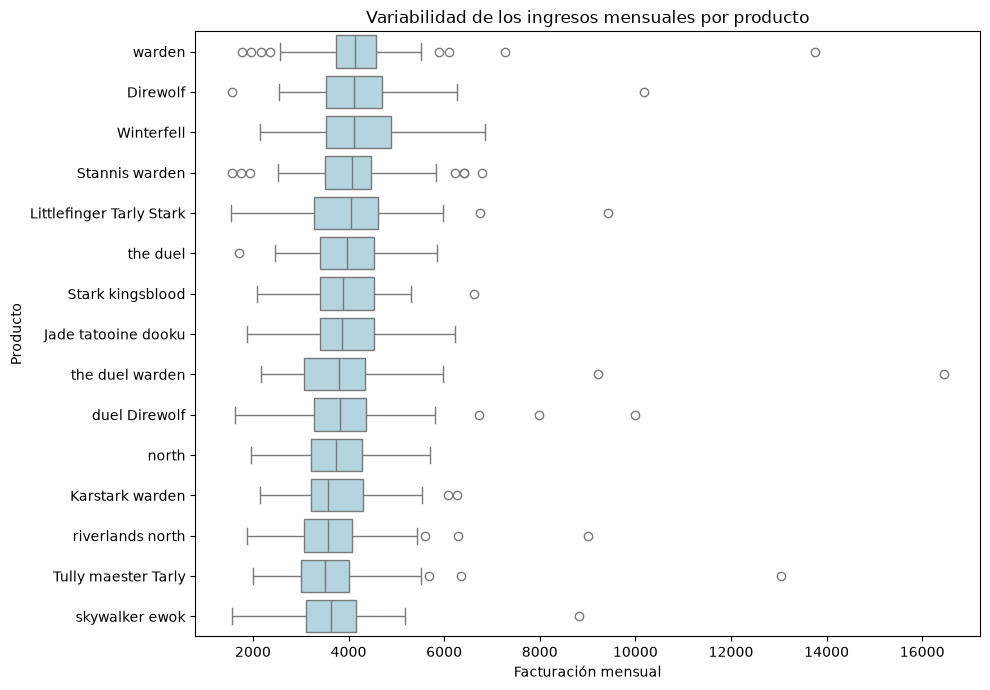

In [57]:
plt.figure(figsize=(10, 7))

sns.boxplot(
    data=ingresos_mensuales_por_producto,
    x="ingreso_mensual",
    y="product_name",
    order=top_15_productos.index.get_level_values("product_name"),
    color="lightblue"
)

plt.title("Variabilidad de los ingresos mensuales por producto")
plt.xlabel("Facturación mensual")
plt.ylabel("Producto")
plt.tight_layout()
plt.show()

Interpretación para el negocio:

Los quince productos con mayores ingresos totales presentan una facturación mensual habitual bastante parecida. Sin embargo, algunos, como «the duel warden» y «warden», tienen meses puntuales en los que facturan mucho más de lo habitual.

Para el negocio, conviene distinguir los ingresos habituales de esos picos excepcionales, para evitar planificar las ventas esperando que todos los meses sean tan buenos. Sería útil investigar qué ocurrió en esos meses —por ejemplo, si hubo promociones o compras de mayor volumen— y comprobar si esas circunstancias pueden repetirse.

#### Pregunta 4. ¿Cómo varía la actividad de venta por franjas horarias a lo largo de los años? (Patrones horarios)

Paso 1. Crear franjas horarias a partir de la hora: crear una función y aplicarla utilizando `apply`.

Primero, al crear la función, utilizo condicionales para clasificar cada hora en madrugada, mañana, tarde o noche. Después, la aplico con .apply() a la columna de horas y guardo el resultado en una nueva columna llamada "franja_horaria".

In [58]:
def crear_franja_horaria(hora):

    if hora >= 0 and hora < 6:
        return "Madrugada"

    elif hora >= 6 and hora < 12:
        return "Mañana"

    elif hora >= 12 and hora < 18:
        return "Tarde"

    elif hora >= 18 and hora < 24:
        return "Noche"

    else:
        return None

In [59]:
df_ventas["franja_horaria"] = df_ventas["hora_transaccion"].apply(crear_franja_horaria)

In [60]:
display(df_ventas[["hora_transaccion", "franja_horaria"]].head(10))

,hora_transaccion,franja_horaria
0,7,Mañana
1,15,Tarde
2,19,Noche
3,18,Noche
4,4,Madrugada
5,0,Madrugada
6,7,Mañana
7,5,Madrugada
8,4,Madrugada
9,23,Noche


Paso 2. Construir una tabla agregada utilizando `crosstab`.

In [61]:
tabla_franjas = pd.crosstab(
    index=df_ventas["anio"],
    columns=df_ventas["franja_horaria"]
)
display(tabla_franjas)

franja_horaria,Madrugada,Mañana,Noche,Tarde
anio,,,,
2015,2431,2443,2478,2425
2016,2454,2461,2373,2481
2017,2425,2456,2421,2531
2018,2496,2410,2430,2487
2019,2437,2536,2429,2526
2020,2591,2445,2520,2453
2021,2569,2555,2505,2569
2022,2548,2431,2539,2497
2023,2492,2528,2434,2448


Se construye esta tabla de frecuencias con `pd.crosstab()`, cruzando el año y la franja horaria. Cada celda muestra el número de ventas aceptadas realizadas en esa franja durante ese año.

#### Paso 3. Visualizar mediante un mapa de calor (`heatmap`).

annot=True: escribe el recuento dentro de cada celda.

fmt=.3f: muestra números enteros, con 3 decimales.

cmap="YlGnBu": utiliza una escala de amarillo, verde y azul; los tonos más oscuros representan más ventas.

cbar_kws: pone el título a la barra de colores.

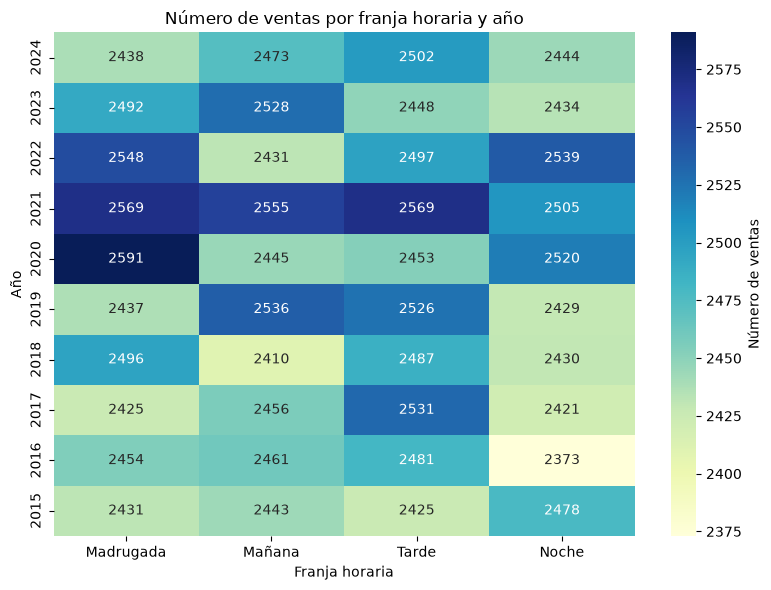

In [62]:
plt.figure (figsize=(8,6))

sns.heatmap(
    data = tabla_franjas[["Madrugada", "Mañana", "Tarde", "Noche"]],
    annot=True,
    fmt="d",
    cmap="YlGnBu",
    cbar_kws={"label": "Número de ventas"}
)

plt.gca().invert_yaxis()
plt.title("Número de ventas por franja horaria y año")
plt.xlabel("Franja horaria")
plt.ylabel("Año")
plt.tight_layout()

plt.show()

Entre 2015 y 2024, las ventas se distribuyen de forma bastante equilibrada entre las cuatro franjas horarias. Los recuentos van de 2.373 a 2.591 ventas por franja y año. Aunque hay diferencias, ninguna franja mantiene el primer puesto durante todo el período: por ejemplo, en 2023 destaca la mañana y en 2024, la tarde.

Para el negocio, esto indica que la actividad se mantiene durante las distintas partes del día y que no hay una franja claramente dominante que justifique concentrar en ella toda las acciones comerciales. Antes de modificar horarios o distribuir recursos, convendría revisar las ventas por hora y día de la semana, porque estos intervalos de seis horas pueden ocultar momentos concretos de mayor actividad.

# Nivel 2 – Análisis relacional y patrones avanzados

## Ejercicio 1: Análisis de productos y captación de usuarios

🎯 Objetivo: Analizar el rendimiento de los productos combinando ingresos, estabilidad y capacidad de captación de nuevos usuarios, con el objetivo de detectar posibles riesgos de negocio asociados a una concentración excesiva de ingresos, la dependencia de usuarios recurrentes y la falta de crecimiento de la base de usuarios.

¿Los productos que generan más ingresos también impulsan el crecimiento del negocio mediante la captación de nuevos usuarios, o el negocio depende principalmente de usuarios recurrentes que compran los mismos productos?

**Pasos orientativos:**

1. Combina las tablas necesarias.

2. Define un criterio de nuevo usuario: si la transacción analizada es la primera cronológicamente en el sistema, crea una variable es_nuevo_usuario = True / False.

3. Agrega la información por producto y calcula las siguientes métricas:

        Ingresos totales.

        Variabilidad de los ingresos.

        Número de nuevos usuarios.

        Porcentaje de nuevos usuarios sobre el total de compradores del producto.

4. Crea una tipología analítica de productos a partir de las métricas calculadas. Por ejemplo:

        Captador: alta captación de nuevos usuarios.

        Recurrente: ingresos elevados, pero baja captación.

        Emergente: baja facturación, pero buena captación.

        Estancado: bajos ingresos y baja captación.

5. Construye una visualización que permita analizar la relación entre las dimensiones principales. Por ejemplo, un gráfico de dispersión (scatter plot) con:

        Eje X: ingresos totales por producto.

        Eje Y: número de nuevos usuarios.

        Tamaño del punto: variabilidad de los ingresos.

        Color del punto: tipología analítica del producto.

📌 Nota importante

No se trata solo de mostrar gráficos, sino de interpretar qué implica para el negocio no captar nuevos usuarios.

**PASO A PASO**

### Paso 1: Combinar las tablas necesarias

Se reutiliza la tabla "combinadas_ventas_productos", creada en el nivel 1, que combina las ventas aceptdas, la tabla puente y los productos, e incluye el ingreso estimado por producto y compra.

In [63]:
display(combinadas_ventas_productos.head())

,id_venta,card_id,business_id,timestamp,amount,declined,product_ids,user_id,lat,longitude,...,id_producto,product_name,price,colour,weight,warehouse_id,category,brand,cost,launch_date
0,00043A49-2949-494B-A5DD-A5BAE3BB19DD,CcS-9294,b-2458,2024-08-28 07:16:46,433.51,0,"16, 26, 97, 87",4713,46.199929,1.435540,...,16,the duel warden,180.91,#666666,3.0,WH-11,Home,NordHaus,101.11,2014-05-31
1,00043A49-2949-494B-A5DD-A5BAE3BB19DD,CcS-9294,b-2458,2024-08-28 07:16:46,433.51,0,"16, 26, 97, 87",4713,46.199929,1.435540,...,26,Stark Karstark,53.01,#898989,2.0,WH-21,Food,GreenFork,30.49,2013-02-15
2,00043A49-2949-494B-A5DD-A5BAE3BB19DD,CcS-9294,b-2458,2024-08-28 07:16:46,433.51,0,"16, 26, 97, 87",4713,46.199929,1.435540,...,87,sith Jade,96.26,#e2e2e2,1.5,WH-82,Food,Market&Co,66.36,2013-11-10
3,00043A49-2949-494B-A5DD-A5BAE3BB19DD,CcS-9294,b-2458,2024-08-28 07:16:46,433.51,0,"16, 26, 97, 87",4713,46.199929,1.435540,...,97,jinn Winterfell,65.25,#bababa,1.0,WH-92,Beauty,CareLab,26.25,2013-02-22
4,00045D6B-ED2E-4F2F-8186-CEE074D875D0,CcS-6699,b-2390,2020-07-14 15:37:45,332.38,0,"30, 11, 16, 81",2118,29.757296,-95.379637,...,11,Karstark Dorne,49.70,#141414,2.7,WH-6,Electronics,Nexa,34.45,2014-09-01


### Paso 2. Define un criterio de nuevo usuario: si la transacción analizada es la primera cronológicamente en el sistema, crea una variable es_nuevo_usuario = True / False.

Primero, ubico la primera compra aceptada cronológicamente por cada usuario.

In [64]:
fecha_primera_compra = combinadas_ventas_productos.groupby("user_id")["timestamp"].min()

display(fecha_primera_compra)

user_id
1      2015-05-08 18:09:41
2      2015-01-13 05:50:19
3      2015-05-04 10:23:38
4      2015-10-25 18:43:29
5      2015-03-28 04:50:05
               ...        
4996   2015-01-07 20:31:38
4997   2015-04-15 19:49:25
4998   2016-06-09 18:34:18
4999   2018-05-26 15:12:45
5000   2015-01-13 23:07:25
Name: timestamp, Length: 5000, dtype: datetime64[us]

Segundo, creo la columna `es_nuevo_usuario` comparando la fecha de cada compra con la primera fecha de compra de su usuario, obtenida mediante `.map()`. La comparación devuelve `True` si coinciden y `False` en caso contrario.

In [65]:
combinadas_ventas_productos["es_nuevo_usuario"] = (
    combinadas_ventas_productos["timestamp"] == combinadas_ventas_productos["user_id"].map(fecha_primera_compra))

In [66]:
display(
    combinadas_ventas_productos["es_nuevo_usuario"]
    .value_counts(dropna=False)
)

es_nuevo_usuario
False    238560
True      12521
Name: count, dtype: int64

In [67]:
display(combinadas_ventas_productos.head())

,id_venta,card_id,business_id,timestamp,amount,declined,product_ids,user_id,lat,longitude,...,product_name,price,colour,weight,warehouse_id,category,brand,cost,launch_date,es_nuevo_usuario
0,00043A49-2949-494B-A5DD-A5BAE3BB19DD,CcS-9294,b-2458,2024-08-28 07:16:46,433.51,0,"16, 26, 97, 87",4713,46.199929,1.435540,...,the duel warden,180.91,#666666,3.0,WH-11,Home,NordHaus,101.11,2014-05-31,False
1,00043A49-2949-494B-A5DD-A5BAE3BB19DD,CcS-9294,b-2458,2024-08-28 07:16:46,433.51,0,"16, 26, 97, 87",4713,46.199929,1.435540,...,Stark Karstark,53.01,#898989,2.0,WH-21,Food,GreenFork,30.49,2013-02-15,False
2,00043A49-2949-494B-A5DD-A5BAE3BB19DD,CcS-9294,b-2458,2024-08-28 07:16:46,433.51,0,"16, 26, 97, 87",4713,46.199929,1.435540,...,sith Jade,96.26,#e2e2e2,1.5,WH-82,Food,Market&Co,66.36,2013-11-10,False
3,00043A49-2949-494B-A5DD-A5BAE3BB19DD,CcS-9294,b-2458,2024-08-28 07:16:46,433.51,0,"16, 26, 97, 87",4713,46.199929,1.435540,...,jinn Winterfell,65.25,#bababa,1.0,WH-92,Beauty,CareLab,26.25,2013-02-22,False
4,00045D6B-ED2E-4F2F-8186-CEE074D875D0,CcS-6699,b-2390,2020-07-14 15:37:45,332.38,0,"30, 11, 16, 81",2118,29.757296,-95.379637,...,Karstark Dorne,49.70,#141414,2.7,WH-6,Electronics,Nexa,34.45,2014-09-01,False


### Paso 3. Agrega la información por producto y calcula las siguientes métricas:

#### Ingresos totales.

Agrupo las ventas por identificador y nombre del producto y sumo `price` para obtener los ingresos totales de cada uno, considerando una unidad vendida por fila.

In [68]:
display(combinadas_ventas_productos.columns)

Index(['id_venta', 'card_id', 'business_id', 'timestamp', 'amount', 'declined',
       'product_ids', 'user_id', 'lat', 'longitude', 'discount_amount',
       'tax_amount', 'shipping_amount', 'channel', 'campaign_id',
       'device_type', 'is_international', 'decline_reason', 'distance_km',
       'hora_transaccion', 'dia_transacciones', 'anio', 'mes',
       'transaction_id', 'product_id', 'id_producto', 'product_name', 'price',
       'colour', 'weight', 'warehouse_id', 'category', 'brand', 'cost',
       'launch_date', 'es_nuevo_usuario'],
      dtype='str')

In [69]:
ingresos_totales_por_producto = (
    combinadas_ventas_productos.groupby(["product_id", "product_name"])["price"]
    .sum()
    .reset_index(name="ingresos_totales"))

display(ingresos_totales_por_producto)

,product_id,product_name,ingresos_totales
0,1,Direwolf Stannis,394719.50
1,2,Tarly Stark,23580.48
2,3,duel tourney Lannister,429022.91
3,4,warden south duel,184254.07
4,5,skywalker ewok,433186.60
...,...,...,...
95,96,dooku solo,52007.12
96,97,jinn Winterfell,164038.50
97,98,Direwolf Littlefinger,97588.18
98,99,the duel,378691.10


#### Variabilidad de los ingresos.

Primero calculo los ingresos mensuales de todos los productos sumando `price` por producto y mes.

Después calculo la desviación estándar de esos totales mensuales para medir cuánto varían respecto a su media. Un valor mayor indica mayores cambios en la facturación mensual.

Primero, preparo el mes de venta para todos los productos:

In [70]:
datos_mensuales_todos = combinadas_ventas_productos.copy()

datos_mensuales_todos["mes_venta"] = (
    datos_mensuales_todos["timestamp"].dt.to_period("M")
)

Segundo, calculo la facturación de cada producto en cada mes:

In [71]:
ingresos_mensuales_todos_productos = (
    datos_mensuales_todos
    .groupby(["product_id", "product_name", "mes_venta"])["price"]
    .sum()
    .reset_index(name="ingreso_mensual")
)

Tercero, calculo cuánto varían esos totales mensuales:

In [72]:
variabilidad_ingresos_por_producto = (
    ingresos_mensuales_todos_productos
    .groupby(["product_id", "product_name"])["ingreso_mensual"]
    .std()
    .reset_index(name="variabilidad_ingresos")
)

display(variabilidad_ingresos_por_producto.round(2))

,product_id,product_name,variabilidad_ingresos
0,1,Direwolf Stannis,1045.49
1,2,Tarly Stark,51.21
2,3,duel tourney Lannister,904.39
3,4,warden south duel,500.14
4,5,skywalker ewok,813.03
...,...,...,...
95,96,dooku solo,148.50
96,97,jinn Winterfell,335.80
97,98,Direwolf Littlefinger,218.76
98,99,the duel,805.29


#### Número de nuevos usuarios.

    Primero creo la condición que filtará la tabla para visualizar solo las filas con las compras primeras de cada usuario.
    Luego, aplico ese filtro al df combinadas_ventas_productos y, finalmente, hago el conteo de usuarios distintos que hay en esas primeras compras, agrupado por producto.

In [73]:
filtro_primeras_compras = combinadas_ventas_productos["es_nuevo_usuario"] == True

In [74]:
nuevos_usuarios_por_producto = (
    combinadas_ventas_productos[filtro_primeras_compras]
    .groupby(["product_id", "product_name"])["user_id"]
    .nunique()
    .reset_index(name="nuevos_usuarios")
)

In [75]:
display(nuevos_usuarios_por_producto)

,product_id,product_name,nuevos_usuarios
0,1,Direwolf Stannis,110
1,2,Tarly Stark,126
2,3,duel tourney Lannister,126
3,4,warden south duel,121
4,5,skywalker ewok,152
...,...,...,...
95,96,dooku solo,99
96,97,jinn Winterfell,121
97,98,Direwolf Littlefinger,120
98,99,the duel,125


#### Porcentaje de nuevos usuarios sobre el total de compradores del producto.

Primero agrupo las ventas por producto y cuento los usuarios distintos con nunique(). Incluyo tanto a los nuevos como a los recurrentes y cuento a cada usuario una sola vez por producto.

In [76]:
total_compradores_por_producto = (combinadas_ventas_productos
.groupby(["product_id", "product_name"])["user_id"]
.nunique()
.reset_index(name="compradores_por_producto_total"))

display(total_compradores_por_producto)


,product_id,product_name,compradores_por_producto_total
0,1,Direwolf Stannis,1890
1,2,Tarly Stark,1949
2,3,duel tourney Lannister,1921
3,4,warden south duel,1945
4,5,skywalker ewok,1932
...,...,...,...
95,96,dooku solo,1912
96,97,jinn Winterfell,1894
97,98,Direwolf Littlefinger,1934
98,99,the duel,1919


Luego, utilizo `pd.merge()` para unir la tabla de nuevos usuarios con la de compradores totales mediante product_id y product_name. Así, los dos recuentos de cada producto quedan en la misma fila.

In [77]:
porcentaje_nuevos_usuarios_sobre_el_total = pd.merge(
    nuevos_usuarios_por_producto,
    total_compradores_por_producto,
    on=["product_id", "product_name"]
)

Después, creo una nueva columna dividiendo el número de nuevos usuarios entre el total de compradores del mismo producto y multiplicando por 100.

In [78]:
porcentaje_nuevos_usuarios_sobre_el_total["porcentaje_nuevos_usuarios"] = (
    porcentaje_nuevos_usuarios_sobre_el_total["nuevos_usuarios"]
    / porcentaje_nuevos_usuarios_sobre_el_total["compradores_por_producto_total"]
    * 100
)

display(porcentaje_nuevos_usuarios_sobre_el_total.round(2))

,product_id,product_name,nuevos_usuarios,compradores_por_producto_total,porcentaje_nuevos_usuarios
0,1,Direwolf Stannis,110,1890,5.82
1,2,Tarly Stark,126,1949,6.46
2,3,duel tourney Lannister,126,1921,6.56
3,4,warden south duel,121,1945,6.22
4,5,skywalker ewok,152,1932,7.87
...,...,...,...,...,...
95,96,dooku solo,99,1912,5.18
96,97,jinn Winterfell,121,1894,6.39
97,98,Direwolf Littlefinger,120,1934,6.20
98,99,the duel,125,1919,6.51


### Pregunta 4. Crea una tipología analítica de productos a partir de las métricas calculadas. Por ejemplo:

        Captador: alta captación de nuevos usuarios.

        Recurrente: ingresos elevados, pero baja captación.

        Emergente: baja facturación, pero buena captación.

        Estancado: bajos ingresos y baja captación.

Primero, combino la tabla de los ingresos totales y la de los datos de nuevos usuarios de cada producto en una nueva ("resumen_productos"), que utilizaré para crear la tipología analítica.

In [79]:
resumen_productos = pd.merge(
    ingresos_totales_por_producto,
    porcentaje_nuevos_usuarios_sobre_el_total,
    on=["product_id", "product_name"]
)

display(resumen_productos.head().round(2))

,product_id,product_name,ingresos_totales,nuevos_usuarios,compradores_por_producto_total,porcentaje_nuevos_usuarios
0,1,Direwolf Stannis,394719.50,110,1890,5.82
1,2,Tarly Stark,23580.48,126,1949,6.46
2,3,duel tourney Lannister,429022.91,126,1921,6.56
3,4,warden south duel,184254.07,121,1945,6.22
4,5,skywalker ewok,433186.60,152,1932,7.87


Segundo, calculo la mediana de los ingresos totales y del número de nuevos usuarios para establecer los límites de la tipología. Considero "altos" los valores iguales o superiores a su respectiva mediana y "bajos" los inferiores.

In [80]:
umbral_ingresos = resumen_productos["ingresos_totales"].median()
umbral_captacion = resumen_productos["nuevos_usuarios"].median()

print(umbral_captacion)
print(umbral_ingresos)

126.0
248887.3


Luego, creo una función que compara los ingresos y el número de nuevos usuarios de cada producto con sus respectivas medianas. Según la combinación de valores altos o bajos, devuelve una tipología: Captador, Recurrente, Emergente o Estancado.

In [81]:
def clasificar_producto(fila):

    if(
        fila["ingresos_totales"] >= umbral_ingresos and
        fila["nuevos_usuarios"] >= umbral_captacion
    ):
        return "Captador"

    elif(
        fila["ingresos_totales"] >= umbral_ingresos and
        fila["nuevos_usuarios"] < umbral_captacion
    ):
        return "Recurrente"

    elif(
        fila["ingresos_totales"] < umbral_ingresos and
        fila["nuevos_usuarios"] >= umbral_captacion
    ):
        return "Emergente"

    else:
        return "Estancado"

Finalmente, aplico la función a cada fila de `resumen_productos` y guardo la categoría obtenida en una nueva columna llamada `tipología`.

In [82]:
resumen_productos["tipología"] = resumen_productos.apply(
    clasificar_producto, axis=1)

display(resumen_productos.head().round(2))

,product_id,product_name,ingresos_totales,nuevos_usuarios,compradores_por_producto_total,porcentaje_nuevos_usuarios,tipología
0,1,Direwolf Stannis,394719.50,110,1890,5.82,Recurrente
1,2,Tarly Stark,23580.48,126,1949,6.46,Emergente
2,3,duel tourney Lannister,429022.91,126,1921,6.56,Captador
3,4,warden south duel,184254.07,121,1945,6.22,Estancado
4,5,skywalker ewok,433186.60,152,1932,7.87,Captador


### Pregunta 5. Construye una visualización que permita analizar la relación entre las dimensiones principales. Por ejemplo, un gráfico de dispersión (scatter plot) con:

        Eje X: ingresos totales por producto.

        Eje Y: número de nuevos usuarios.

        Tamaño del punto: variabilidad de los ingresos.

        Color del punto: tipología analítica del producto.

Primero, incorporamos la variabilidad de los ingresos a la tabla "resumen_productos", y poder crear el gráfico.

Entonces realizamos un merge.

In [83]:
datos_grafico_productos = pd.merge(
    resumen_productos,
    variabilidad_ingresos_por_producto,
    on=["product_id", "product_name"]
)

Segundo,

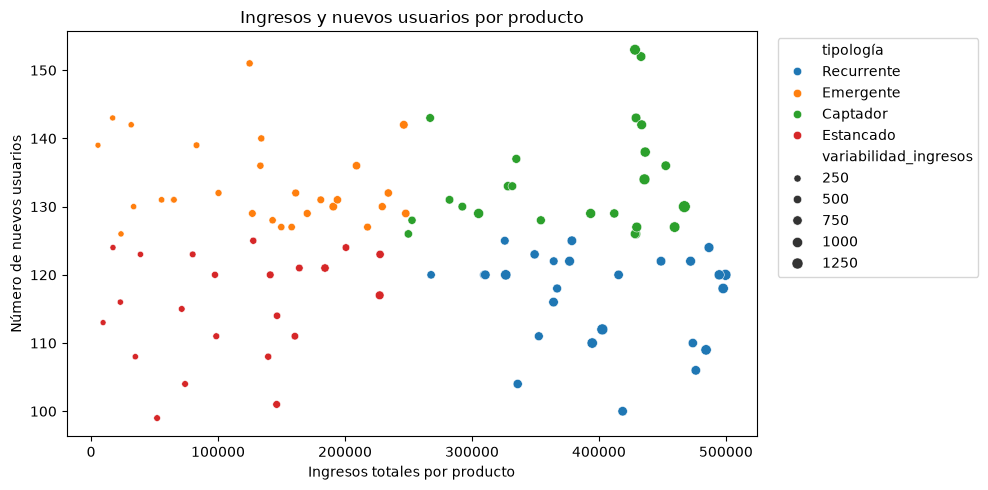

In [84]:
plt.figure(figsize=(10,5))

sns.scatterplot(
    data=datos_grafico_productos,
    x="ingresos_totales",
    y="nuevos_usuarios",
    size="variabilidad_ingresos",
    hue="tipología"
)

plt.title("Ingresos y nuevos usuarios por producto")
plt.xlabel("Ingresos totales por producto")
plt.ylabel("Número de nuevos usuarios")
plt.legend(
    loc="upper left",
    bbox_to_anchor=(1.02,1)
)

plt.tight_layout()
plt.show()

**Interpretación del gráfico y para el negocio.**

El gráfico muestra que los productos con mayores ingresos no siempre aparecen en las primeras compras de más usuarios. Entre ellos encontramos tanto productos captadores —verdes— como recurrentes —azules—, que tienen una menor captación respecto a la mediana.

Los productos emergentes —naranjas— presentan ingresos inferiores a la mediana, pero aparecen en las primeras compras de un número de usuarios igual o superior a ella. Los estancados —rojos— quedan por debajo de ambas medianas. Además, los puntos más grandes representan productos cuya facturación mensual presenta una mayor dispersión en términos monetarios.

Para el negocio, los productos emergentes podrían ser candidatos para probar acciones de promoción y comprobar si ayudan a atraer compradores. En los estancados, convendría comprobar si sus menores ingresos se deben a que se venden pocas veces o a que tienen un precio por unidad más bajo, y revisar su rentabilidad antes de invertir en publicidad.

También es importante mantener la llegada de nuevos compradores: si el negocio dependiera principalmente de los actuales y estos redujeran sus compras, podría resultar difícil compensar la pérdida de ingresos. Este gráfico permite identificar productos que investigar, pero no demuestra que causen la captación ni que esta sea suficiente; para valorarlo habría que analizar su evolución en el tiempo y cuántos nuevos compradores vuelven a comprar.

## Ejercicio 2: Análisis geográfico entre compañías y usuarios y oportunidades de expansión

🎯 Objetivo: Analizar la relación entre el país de las compañías vendedoras, el país de residencia de los usuarios y el flujo de compras entre países.

¿El negocio se basa en mercados locales —el usuario y la compañía pertenecen al mismo país— o existe una oportunidad real de expansión internacional abriendo más compañías en determinados países?

Pasos orientativos:

1. Combina las tablas necesarias.

2. Crea una variable clave para el análisis: compra_local = True / False.

3. Analiza el comportamiento global:

        * Porcentaje de transacciones locales frente a internacionales.

        * Porcentaje de facturación local frente a internacional.

4. Realiza un análisis por país del usuario. Para cada país, calcula:

        * Porcentaje de compras a compañías del mismo país.

        * Porcentaje de compras a compañías extranjeras.

        * Importe total comprado.

5. Realiza un análisis por país de la compañía. Para cada país, calcula qué parte de su facturación procede de:

        * Usuarios locales.

        * Usuarios extranjeros.

6. Escoge una visualización que explique claramente el fenómeno.

7. Realiza una interpretación estratégica:

        * ¿En qué países valdría la pena abrir más compañías locales?

        * ¿Hay países con demanda, pero poca oferta local?

        * ¿El negocio depende demasiado de compañías de un solo país?

        * ¿Abrir compañías locales reduciría las dificultades de compra o mejoraría la conversión?

**PASO A PASO**

### Paso 1. Combinar las tablas necesarias.

Primero cargo la tabla users desde MySQL.

In [85]:
df_users = pd.read_sql("SELECT * FROM users", engine)

display(df_users.head())

,id,name,surname,phone,email,birth_date,country,city,postal_code,address,signup_date,user_segment,income_band
0,1,Zeus,Gamble,1-282-581-0551,interdum.enim@protonmail.edu,1985-11-17,United States,New York,10001,348-7818 Sagittis St.,2014-04-23,young_professional,high
1,2,Garrett,Mcconnell,(718) 257-2412,integer.vitae.nibh@protonmail.org,1992-08-23,United States,Philadelphia,19101,903 Sit Ave,2014-07-04,young_professional,high
2,3,Ciaran,Harrison,(522) 598-1365,interdum.feugiat@aol.org,1998-04-29,United States,Houston,77001,736-2063 Tellus St.,2014-02-15,frequent_shopper,high
3,4,Howard,Stafford,1-411-740-3269,ornare.egestas@icloud.edu,1989-02-18,United States,Phoenix,85001,Ap #545-2244 Erat. Rd.,2014-08-21,premium,high
4,5,Hayfa,Pierce,1-554-541-2077,et.malesuada.fames@hotmail.org,1998-09-26,United States,Philadelphia,19101,341-2821 Ultrices Av.,2013-04-28,frequent_shopper,high


Segundo, renombro `id` como `user_id`para aclarar mejor qué identifica y permitir que coincida con la columna de ventas.

También se hará lo mismo con `country` como `país_usuario`, para distringuirlo del país de la companía cuando combine las tablas.

In [86]:
df_users = df_users.rename(
    columns={
        "id": "user_id",
        "country": "país_usuario"
    }
)
display(df_users.head())

,user_id,name,surname,phone,email,birth_date,país_usuario,city,postal_code,address,signup_date,user_segment,income_band
0,1,Zeus,Gamble,1-282-581-0551,interdum.enim@protonmail.edu,1985-11-17,United States,New York,10001,348-7818 Sagittis St.,2014-04-23,young_professional,high
1,2,Garrett,Mcconnell,(718) 257-2412,integer.vitae.nibh@protonmail.org,1992-08-23,United States,Philadelphia,19101,903 Sit Ave,2014-07-04,young_professional,high
2,3,Ciaran,Harrison,(522) 598-1365,interdum.feugiat@aol.org,1998-04-29,United States,Houston,77001,736-2063 Tellus St.,2014-02-15,frequent_shopper,high
3,4,Howard,Stafford,1-411-740-3269,ornare.egestas@icloud.edu,1989-02-18,United States,Phoenix,85001,Ap #545-2244 Erat. Rd.,2014-08-21,premium,high
4,5,Hayfa,Pierce,1-554-541-2077,et.malesuada.fames@hotmail.org,1998-09-26,United States,Philadelphia,19101,341-2821 Ultrices Av.,2013-04-28,frequent_shopper,high


Luego realizo la combinación de las tablas df_ventas_companies (la que se usó en el nivel 1) con df_users, mediante la columna user_id. De esta manera, se reúne en una misma tabla el importe de cada compra, el país de la compañía y el país del usuario.

In [87]:
df_ventas_companies_users = pd.merge(
    df_ventas_companies,
    df_users,
    how="left",
    on="user_id"
)

display(df_ventas_companies_users.head())

,id,card_id,business_id,timestamp,amount,declined,product_ids,user_id,lat,longitude,...,phone_y,email_y,birth_date,país_usuario,city,postal_code,address,signup_date,user_segment,income_band
0,00043A49-2949-494B-A5DD-A5BAE3BB19DD,CcS-9294,b-2458,2024-08-28 07:16:46,433.51,0,"16, 26, 97, 87",4713,46.199929,1.435540,...,+87-307-6702,gxnmjn.fjycossj@example.com,1996-01-28,France,Marseille,13001,471 Fjycossj St,2013-01-18,frequent_shopper,high
1,00045D6B-ED2E-4F2F-8186-CEE074D875D0,CcS-6699,b-2390,2020-07-14 15:37:45,332.38,0,"30, 11, 16, 81",2118,29.757296,-95.379637,...,+63-443-9528,wolake.ukynumly@example.com,1995-09-04,United States,Houston,77001,48 Ukynumly St,2014-01-07,premium,very_high
2,000481C3-1C26-4FEF-83A0-4CD0EB004BBD,CcS-6696,b-2230,2017-09-04 19:44:53,175.00,0,72,2115,53.548884,-113.503053,...,+38-316-6815,umhwoi.ubmdxvmz@example.com,1969-02-19,Canada,Edmonton,T5A 0A1,228 Ubmdxvmz St,2013-08-15,occasional,low
3,00051AA4-9CBE-4268-B070-C38062A1B3E2,CcS-7606,b-2266,2017-01-05 18:19:25,158.55,0,18,3025,52.208370,5.690806,...,+96-354-2022,qpfyfa.mtnpfdfq@example.com,1961-02-08,Netherlands,Groningen,9711,178 Mtnpfdfq St,2013-06-24,occasional,medium
4,0008A312-EDFE-4A4F-BC99-E9C92EC3CA4D,CcU-3358,b-2598,2023-09-23 04:51:43,317.97,0,"35, 33, 19",215,53.553486,-113.499134,...,058-771-3718,interdum.enim.non@protonmail.edu,1996-05-02,Canada,Edmonton,T5A 0A1,270-2964 Aliquet Avenue,2013-10-12,young_professional,medium


### Paso 2. Crea una variable clave para el análisis: compra_local = True / False.



Creo la columna `compra_local` comparando el país de la compañía con el país del usuario. La compra se considera local si ambos coinciden e internacional si son diferentes.

In [88]:
df_ventas_companies_users["compra_local"] = (
    df_ventas_companies_users["country"]
    == df_ventas_companies_users["país_usuario"]
)

In [89]:
display(df_ventas_companies_users[
    ["country", "país_usuario", "compra_local"]
].head(10))

,country,país_usuario,compra_local
0,Netherlands,France,False
1,Ireland,United States,False
2,United States,Canada,False
3,Sweden,Netherlands,False
4,Belgium,Canada,False
5,Sweden,Netherlands,False
6,Canada,Canada,True
7,Sweden,United Kingdom,False
8,Germany,Netherlands,False
9,Belgium,United States,False


### Paso 3. Analiza el comportamiento global:

#### * Porcentaje de transacciones locales frente a internacionales.

Utilizo `value_counts()` para contar las compras locales e internacionales. Al añadir `normalize=True`, cada recuento se divide entre el total de compras. Después multiplico por 100 para obtener el porcentaje de cada grupo.

In [90]:
porcentaje_transacciones = (
    df_ventas_companies_users["compra_local"]
    .value_counts(normalize=True)*100
)
display(porcentaje_transacciones.round(2))

compra_local
False    88.13
True     11.87
Name: proportion, dtype: float64

#### * Porcentaje de facturación local frente a internacional.

Primero, calculo la facturación de cada grupo:

In [91]:
facturacion_por_grupo = (
    df_ventas_companies_users
    .groupby("compra_local")["amount"].sum()
)

Luego divido la facturación de cada grupo entre la facturación total y multiplico por 100:

In [92]:
porcentaje_facturacion = (
    facturacion_por_grupo / facturacion_por_grupo.sum() * 100)

display(porcentaje_facturacion.round(2))

compra_local
False    88.11
True     11.89
Name: amount, dtype: float64

Aproximadamente, 88 de cada 100 unidades monetarias facturadas corresponden a compras entre usuarios y compañías de países distintos.

### Paso 4. Realiza un análisis por país del usuario. Para cada país, calcula:

#### * Porcentaje de compras a compañías del mismo país.

Agrupo las compras por país del usuario y calculo, dentro de cada país, el porcentaje de compras a compañías locales y extranjeras.

Y solo visualizo las compras a compañías del mismo país.

In [93]:
porcentaje_compras_pais = (
    (df_ventas_companies_users
    .groupby("país_usuario")["compra_local"]
    .value_counts(normalize=True)*100)
    .reset_index(name="porcentaje_compras_pais")
)

display(
    porcentaje_compras_pais[
        porcentaje_compras_pais["compra_local"] == True
    ].round(2)
)

,país_usuario,compra_local,porcentaje_compras_pais
1,Canada,True,9.72
3,France,True,6.28
5,Germany,True,16.95
7,Italy,True,17.11
9,Netherlands,True,19.36
13,Spain,True,1.73
15,Sweden,True,21.34
17,United Kingdom,True,17.29
19,United States,True,18.55


#### * Porcentaje de compras a compañías extranjeras.

Uso el mismo cálculo de porcentaje_compras_pais pero al momento de visualizar, solo escojo el de False.

In [94]:
display(
    porcentaje_compras_pais[
        porcentaje_compras_pais["compra_local"] == False
    ].round(2)
)

,país_usuario,compra_local,porcentaje_compras_pais
0,Canada,False,90.28
2,France,False,93.72
4,Germany,False,83.05
6,Italy,False,82.89
8,Netherlands,False,80.64
10,Poland,False,100.00
11,Portugal,False,100.00
12,Spain,False,98.27
14,Sweden,False,78.66
16,United Kingdom,False,82.71


#### * Importe total comprado.

Sumo los importes de las compras realizadas por los usuarios de cada país para obtener su importe total comprado.

In [95]:
importe_total_por_pais_usuario = (
    df_ventas_companies_users
    .groupby("país_usuario")["amount"]
    .sum()
    .reset_index(name="ingreso_total_por_pais_usuario")
)
display(importe_total_por_pais_usuario)

,país_usuario,ingreso_total_por_pais_usuario
0,Canada,2650339.29
1,France,2467840.16
2,Germany,2550878.07
3,Italy,2585429.93
4,Netherlands,2651840.50
5,Poland,2491052.36
6,Portugal,2615801.06
7,Spain,2668434.76
8,Sweden,2473822.29
9,United Kingdom,2819917.93


### Paso 5. Realiza un análisis por país de la compañía. Para cada país, calcula qué parte de su facturación procede de:

        * Usuarios locales.

        * Usuarios extranjeros.


Agrupo por country (país de la compañía) y por compra_local, que distingue usuarios locales (True) y extranjeros (False). Después sumo amount para obtener la facturación total de cada grupo.

In [96]:
facturacion_por_pais_compania = (
    df_ventas_companies_users
    .groupby(["country", "compra_local"])["amount"]
    .sum()
    .reset_index(name="facturacion")
)

display(facturacion_por_pais_compania.round(2))

,country,compra_local,facturacion
0,Australia,False,687532.20
1,Belgium,False,937789.26
2,Canada,False,297261.09
3,Canada,True,254806.44
4,China,False,235421.76
5,France,False,1252902.50
6,France,True,153765.65
7,Germany,False,3540549.43
8,Germany,True,444114.60
9,Ireland,False,707379.30


La tabla permite identificar cuánto facturan las compañías de cada país a usuarios locales y extranjeros.

Por ejemplo, las compañías de Canadá obtienen 297.261,09 de usuarios extranjeros y 254.806,44 de usuarios locales. Por tanto, reciben ingresos de ambos grupos, con una aportación algo mayor de los extranjeros. En Australia, Bélgica y China solo aparece facturación procedente de usuarios extranjeros en las ventas analizadas.

Para el negocio, estos resultados permiten identificar qué países vendedores se apoyan más en compradores internacionales. Sin embargo, no indican por qué estos usuarios compran allí ni demuestran que abrir compañías en sus países de residencia aumentaría las ventas.

### Paso 6. Escoge una visualización que explique claramente el fenómeno.

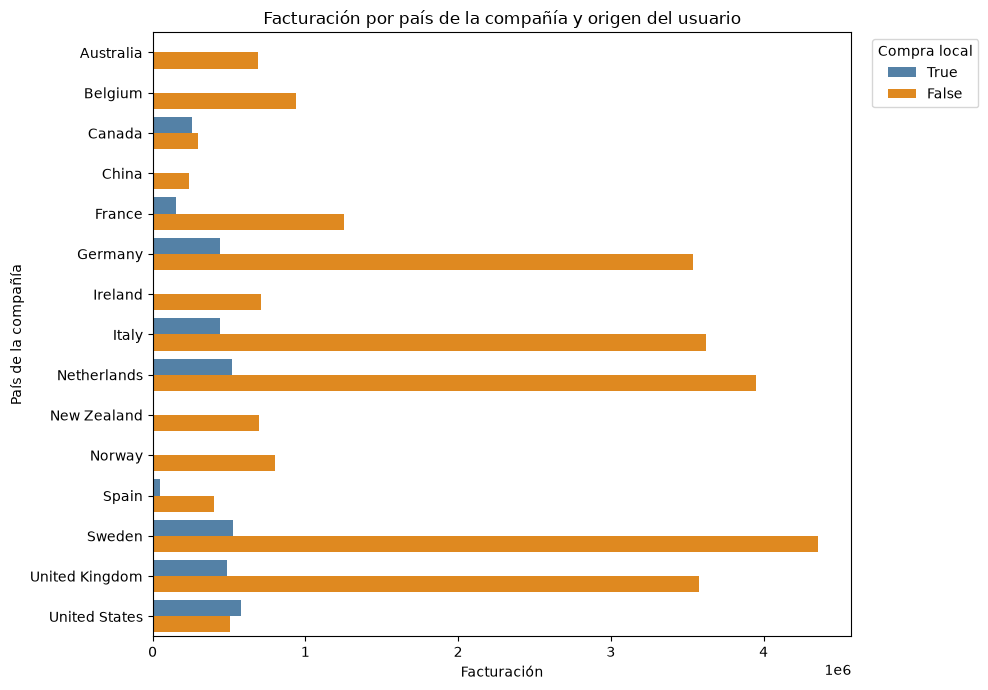

In [97]:
plt.figure(figsize=(10, 7))

sns.barplot(
    data=facturacion_por_pais_compania,
    x="facturacion",
    y="country",
    hue="compra_local",
    hue_order=[True, False],
    palette={True: "steelblue", False: "darkorange"}
)

plt.title("Facturación por país de la compañía y origen del usuario")
plt.xlabel("Facturación")
plt.ylabel("País de la compañía")

plt.legend(
    title="Compra local",
    loc="upper left",
    bbox_to_anchor=(1.02, 1)
)

plt.tight_layout()
plt.show()

La facturación del negocio procede principalmente de usuarios que compran a compañías situadas en un país diferente al suyo: estas compras representan el 88,11 % de la facturación total, frente al 11,89 % de las compras locales. Por tanto, el negocio presenta una actividad principalmente internacional.

El gráfico permite comparar cuánto facturan las compañías de cada país a usuarios locales y extranjeros, e identificar los países que más ingresos aportan.


### Paso 7. Realiza una interpretación estratégica:

#### * ¿En qué países valdría la pena abrir más compañías locales?

Primero elaboro un gráfico con los datos del paso 4 para comparar, en cada país del usuario, el porcentaje de compras a compañías locales y extranjeras.

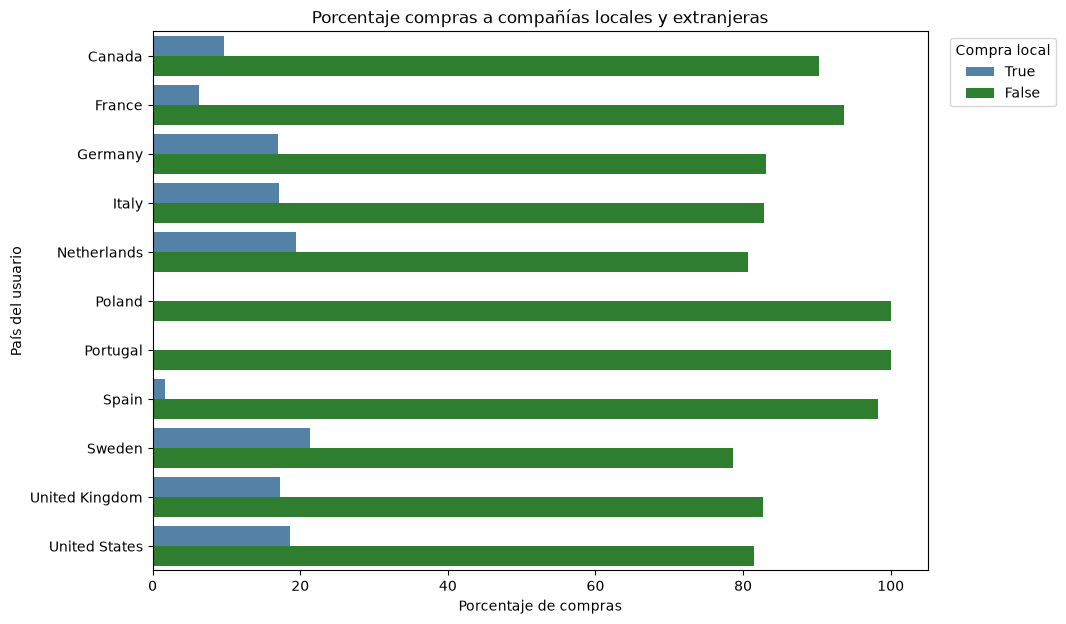

In [98]:
plt.figure(figsize=(10,7))

sns.barplot(
    data=porcentaje_compras_pais,
    x="porcentaje_compras_pais",
    y="país_usuario",
    hue="compra_local",
    hue_order=[True, False],
    palette={True: "steelblue", False: "forestgreen"}
)

plt.title("Porcentaje compras a compañías locales y extranjeras")
plt.xlabel("Porcentaje de compras")
plt.ylabel("País del usuario")

plt.legend(
    title="Compra local",
    loc="upper left",
    bbox_to_anchor=(1.02, 1)
)

plt.show()

Este gráfico compara los porcentajes de compras a compañías locales y extranjeras según el país del usuario. En Polonia y Portugal, el 100 % de las compras registradas se realiza a compañías extranjeras. En los demás países también predominan las compras internacionales, con porcentajes superiores al 78 %.

Estos resultados permiten plantear si habría oportunidades para abrir compañías locales en los países de los compradores. Sin embargo, todavía no permiten recomendar un país concreto ni explicar por qué sus usuarios compran principalmente fuera.

Para identificar candidatos, debemos comparar estos porcentajes con el importe total comprado por los usuarios de cada país, que ya hemos calculado en el paso 4.

Entonces, al comparar ambos gráficos, podré identificar qué países combinan un alto porcentaje de compras internacionales y un importe total comprado elebado, para identificarlos como candidatos a investigar.

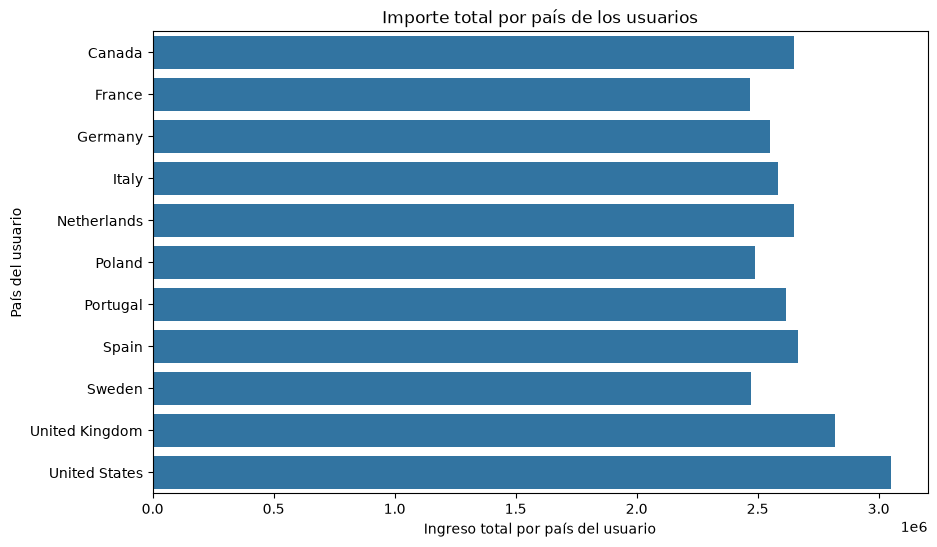

In [99]:
plt.figure(figsize=(10,6))

sns.barplot(
    data=importe_total_por_pais_usuario,
    x="ingreso_total_por_pais_usuario",
    y="país_usuario"
)

plt.title("Importe total por país de los usuarios")
plt.xlabel("Ingreso total por país del usuario")
plt.ylabel("País del usuario")

plt.show()

**Interpretación:**

Estados Unidos y Reino Unido destacan por presentar los mayores importes totales comprados y porcentajes de compras internacionales superiores al 80 %. Canadá y Francia también serían candidatos para investigar, porque combinan importes importantes con porcentajes internacionales del 90,28 % y del 93,72 %, respectivamente.

España, Polonia y Portugal merecen atención porque sus compras son casi exclusivamente internacionales y sus importes totales son comparables a los de otros países analizados.

Por tanto, estos países presentan motivos para estudiar una posible ampliación de la oferta local. Los gráficos no permiten establecer una prioridad definitiva: para decidir dónde abrir compañías habría que analizar la oferta existente, las necesidades de los compradores y los costes de operar en cada país.

#### * ¿Hay países con demanda, pero poca oferta local?

Primero, necesitamos comprobar cuántas compañías locales hay registradas en cada país. Usamos df_companies, donde cada compañía aparece una vez. Todo esto para comparar su presencia local con las compras realizadas por los usuarios de ese país.

In [100]:
df_companies.columns

Index(['company_id', 'company_name', 'phone', 'email', 'country', 'website',
       'merchant_category', 'merchant_price_position'],
      dtype='str')

In [101]:
companias_por_pais = (
    df_companies.groupby("country")["company_id"]
    .nunique()
    .sort_values()
)
display(companias_por_pais)

country
Spain              1
China              2
France             3
Canada             5
Ireland            6
Australia          6
New Zealand        6
Norway             7
Belgium            8
Germany            8
Italy              9
United Kingdom     9
United States      9
Netherlands       10
Sweden            11
Name: company_id, dtype: int64

**Interpretación general**

Sí, se observan países con actividad de compra y una presencia local de compañías limitada o inexistente en el dataset.

Polonia y Portugal presentan importes totales comprados de aproximadamente 2,5–2,6 millones por país, pero no tienen compañías locales registradas. Esto explica que el 100 % de sus compras sea internacional. 

España también destaca: cuenta con una sola compañía local y el 98,27 % de las compras de sus usuarios se realiza a compañías extranjeras.

Estos países serían candidatos para investigar una posible ampliación de la oferta local, comprobando qué productos buscan sus compradores y si las nuevas compañías podrían ofrecerles ventajas.

#### * ¿El negocio depende demasiado de compañías de un solo país?

Reutilizo la facturación por país calculada en el nivel 1. Identifico el país con mayores ingresos y calculo qué porcentaje representa sobre la facturación total para valorar la dependencia de un único país.

In [102]:
pais_principal = facturacion_por_pais_ordenada.index[0]

porcentaje_pais_principal = (
    facturacion_por_pais_ordenada.iloc[0] / facturacion_por_pais_ordenada.sum() * 100
)

print(pais_principal, round(porcentaje_pais_principal, 2), "%")

Sweden 16.83 %


No se observa una dependencia excesiva de compañías de un solo país. Suecia es el país vendedor con mayor facturación y representa el 16,83 % del total; el 83,17 % restante procede de compañías de otros países.

Aun así, perder las ventas de las compañías suecas tendría un impacto importante. Además, como se observó en el nivel 1, existe concentración de ingresos en un grupo reducido de países. Por tanto, conviene distinguir entre depender de un único país y concentrar buena parte de la facturación en varios.

#### * ¿Abrir compañías locales reduciría las dificultades de compra o mejoraría la conversión?

Abrir compañías locales podría facilitar las compras si permitiera resolver dificultades concretas, como problemas con el idioma, los medios de pago o la atención al cliente. Sin embargo, la ubicación local por sí sola no garantiza una mejora.

Con los datos analizados no podemos afirmar que aumentaría la conversión, porque hemos estudiado ventas aceptadas y no sabemos cuántas personas abandonaron la compra ni por qué lo hicieron. El elevado porcentaje de compras internacionales tampoco quiere decir que los compradores hayan tenido dificultades.

Para comprobarlo, sería necesario analizar los abandonos y los problemas durante el proceso de compra, y realizar una prueba para observar si una oferta local consigue que una mayor proporción de personas complete sus compras.

# Nivel 3 — Visualización ejecutiva y storytelling

## Ejercicio 1: Mini-dashboard departamental

🎯 Objetivo: Construye un mini-dashboard en Python utilizando Google Colab. 

    Este ejercicio está pensado para que todo el desarrollo principal se realice dentro del notebook, utilizando Colab como herramienta de análisis y visualización.

La opción principal y recomendada es la siguiente:

1. Figura única con subplots (enfoque analítico clásico)

    Construcción de una única figura con 4 subplots utilizando Matplotlib y/o Seaborn.

    Requisitos:

        * 1 figura.

        * 4 visualizaciones diferentes.

    Si tienes tiempo y quieres profundizar en una solución algo más compleja, a continuación se presentan opciones avanzadas opcionales:

    Google Colab está pensado principalmente para el trabajo analítico en notebooks. Por este motivo, no se recomienda construir dashboards con Streamlit o Dash dentro de Colab, ya que requieren ejecutar aplicaciones web en un entorno local.

    Las opciones de dashboard con Streamlit o Dash se consideran avanzadas y opcionales, y solo deben desarrollarse en un entorno local de Python.

2. Dashboard interactivo con Streamlit

    Construcción de una aplicación sencilla con Streamlit, orientada a la exploración interactiva.

    Requisitos:

        * 1 página de Streamlit.

        * Al menos:
        
            º 2 filtros.

            º Entre 3 y 4 visualizaciones.

        * Uso de st.sidebar o selectores.

3. Dashboard con Dash

    Construcción de un dashboard web con Plotly Dash.

    Requisitos:

        * Diseño con componentes.

        * Callbacks sencillos.

        * Al menos 3 visualizaciones conectadas.

📌 Condición común a TODAS las opciones

Independientemente de la opción elegida, el mini-dashboard debe estar orientado a UNO de los siguientes departamentos:

        Marketing.

        Ventas / Comercial.

        Producción.

        Sistemas / Ciberseguridad.

Las visualizaciones deben ser:

        Relevantes para el departamento elegido.

        Claras y legibles.

        Coherentes entre sí.

👉 No se valora la complejidad gráfica, sino:

        La selección adecuada de métricas.

        La capacidad de síntesis.

        La coherencia del mensaje.

### Pregunta 1. Figura única con subplots (enfoque analítico clásico)

    Construcción de una única figura con 4 subplots utilizando Matplotlib y/o Seaborn.

    Requisitos:

        * 1 figura.

        * 4 visualizaciones diferentes.

**Departamento elegido: Ventas / Comercial.**

El mini-dashboard está dirigido al departamento de Ventas / Comercial. 

Su objetivo es resumir la evolución de la facturación, los países vendedores que más ingresos aportan, los patrones horarios de venta y la distribución de los importes de las compras.

**Construcción de la figura y subplots**

Creo una figura dividida en dos filas y dos columnas mediante `plt.subplots(2, 2)`. La variable `fig` representa la figura completa y `axes` contiene los cuatro espacios donde colocaré los gráficos. 

Primero preparo la estructura del mini-dashboard y después añadiré cada visualización.

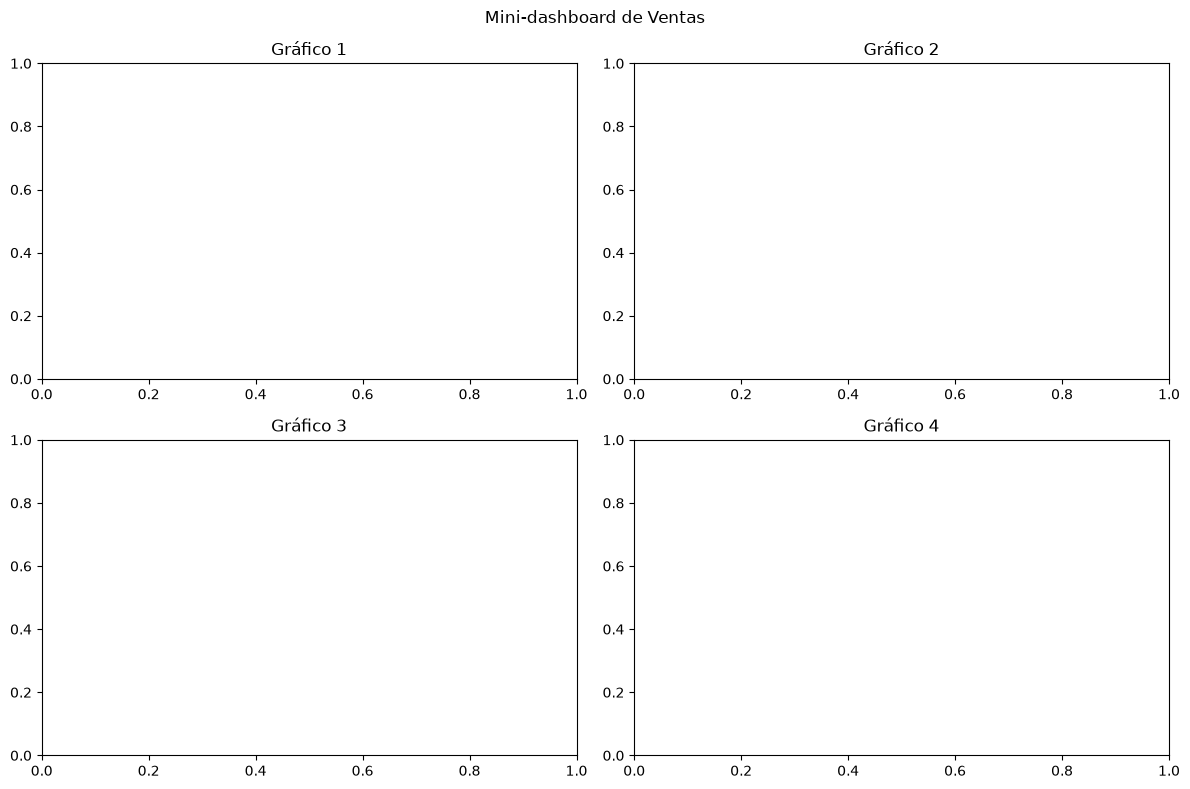

In [103]:
fig, axes = plt.subplots(2,2, figsize=(12,8))

fig.suptitle("Mini-dashboard de Ventas")

axes[0,0].set_title("Gráfico 1")
axes[0,1].set_title("Gráfico 2")
axes[1,0].set_title("Gráfico 3")
axes[1,1].set_title("Gráfico 4")

plt.tight_layout()

plt.show()

Luego voy creando gráficos, cuadrante por cuadrante. Primero el cuadrante [0,0] con la evolución mensual de la facturación.

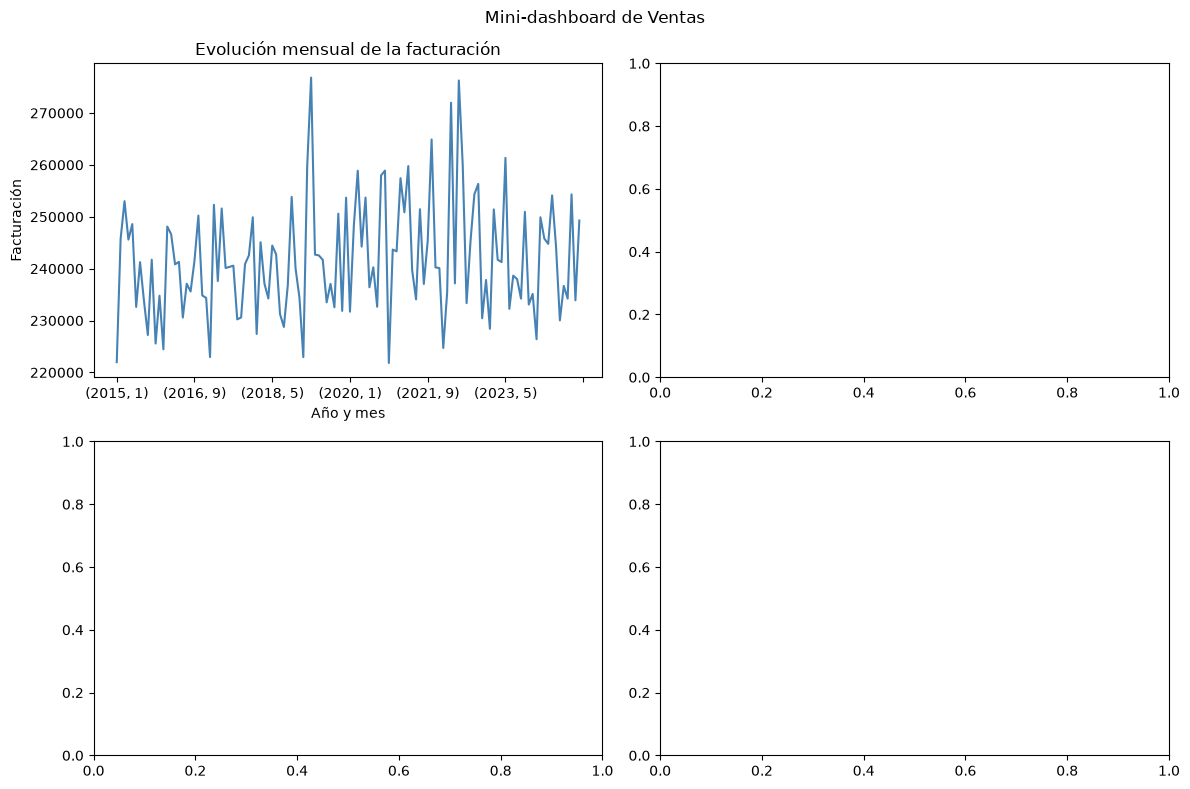

In [104]:
fig, axes = plt.subplots(2,2, figsize=(12,8))

fig.suptitle("Mini-dashboard de Ventas")

ventas_mensuales.plot(
    kind="line",
    ax=axes[0, 0],
    color="steelblue"
)

axes[0, 0].set_title("Evolución mensual de la facturación")
axes[0, 0].set_xlabel("Año y mes")
axes[0, 0].set_ylabel("Facturación")

plt.tight_layout()
plt.show()

Ahora creamos el gráfico del 2do cuadrante [0,1], con la facturación por país de las compañías, usando facturación_por_pais_ordenada que ya se calculó anteriormente.

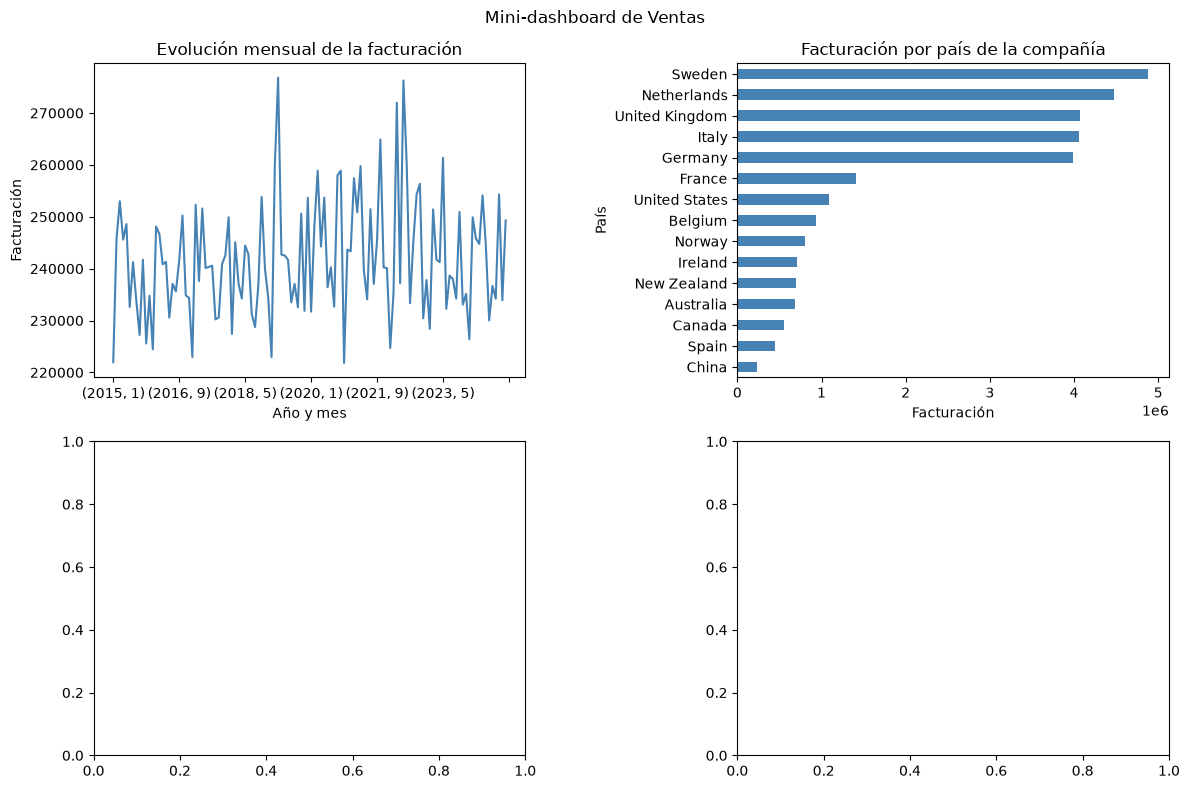

In [105]:
# 1er gráfico
fig, axes = plt.subplots(2,2, figsize=(12,8))

fig.suptitle("Mini-dashboard de Ventas")

ventas_mensuales.plot(
    kind="line",
    ax=axes[0, 0],
    color="steelblue"
)

axes[0, 0].set_title("Evolución mensual de la facturación")
axes[0, 0].set_xlabel("Año y mes")
axes[0, 0].set_ylabel("Facturación")

# 2do gráfico
facturacion_por_pais_ordenada.plot(
    kind="barh",
    ax=axes[0, 1],
    color="steelblue"
)

axes[0, 1].set_title("Facturación por país de la compañía")
axes[0, 1].set_xlabel("Facturación")
axes[0, 1].set_ylabel("País")
axes[0, 1].invert_yaxis()

plt.tight_layout(w_pad=5)
plt.show()

Luego, continuamos con el 3er gráfico, que será un mapa de calor de ventas por año y franja horaria, usando `tabla_franjas`que ya se calculó antes.

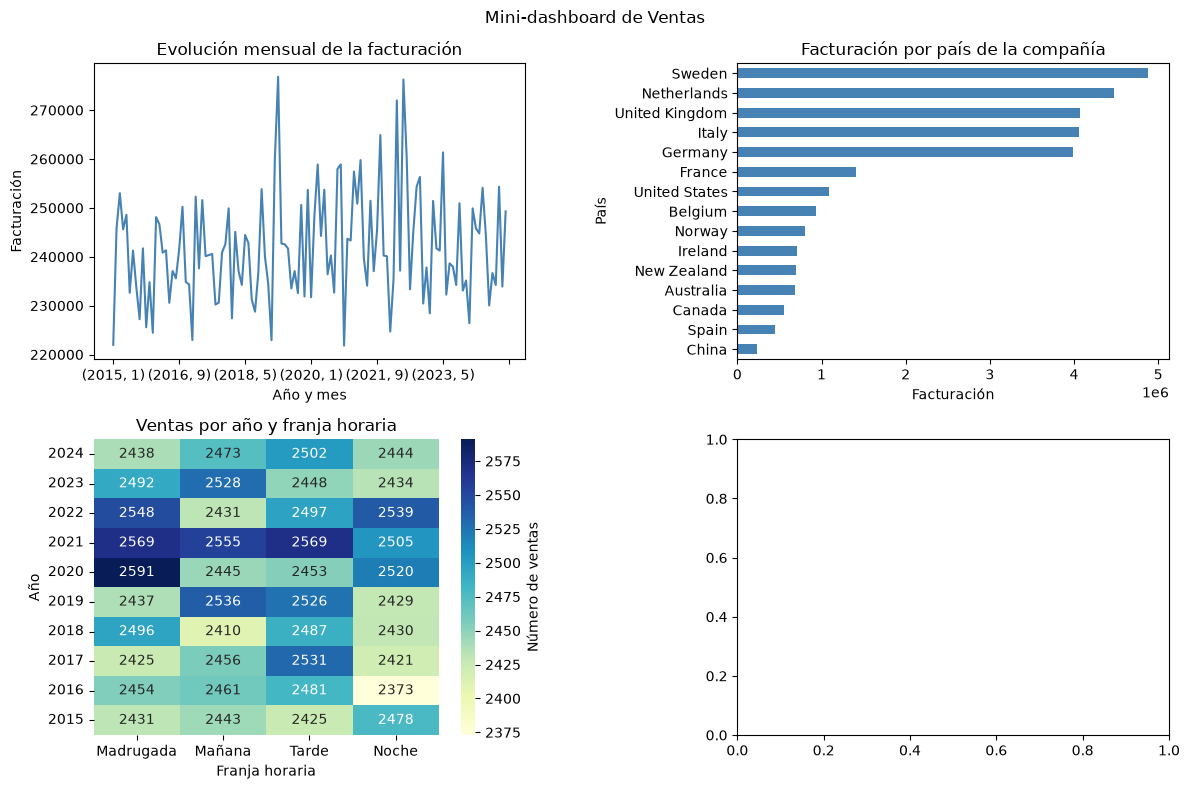

In [106]:
fig, axes = plt.subplots(2,2, figsize=(12,8))

fig.suptitle("Mini-dashboard de Ventas")

ventas_mensuales.plot(
    kind="line",
    ax=axes[0, 0],
    color="steelblue"
)

axes[0, 0].set_title("Evolución mensual de la facturación")
axes[0, 0].set_xlabel("Año y mes")
axes[0, 0].set_ylabel("Facturación")


# 2do gráfico
facturacion_por_pais_ordenada.plot(
    kind="barh",
    ax=axes[0, 1],
    color="steelblue"
)

axes[0, 1].set_title("Facturación por país de la compañía")
axes[0, 1].set_xlabel("Facturación")
axes[0, 1].set_ylabel("País")
axes[0, 1].invert_yaxis()

# 3er gráfico
sns.heatmap(
    tabla_franjas[["Madrugada", "Mañana", "Tarde", "Noche"]],
    annot= True,
    fmt="d",
    cmap="YlGnBu",
    cbar_kws= {"label": "Número de ventas"},
    ax=axes[1,0]
)

axes[1, 0].set_title("Ventas por año y franja horaria")
axes[1, 0].set_xlabel("Franja horaria")
axes[1, 0].set_ylabel("Año")
axes[1, 0].invert_yaxis()

plt.tight_layout(w_pad=5)
plt.show()

Finalmente, el cuarto gráfico del cuadrante [1,1] será un boxplot para comparar los importes de las compras según el día de la semana. Así podremo ver sus medianas y cuánto varían los importes.

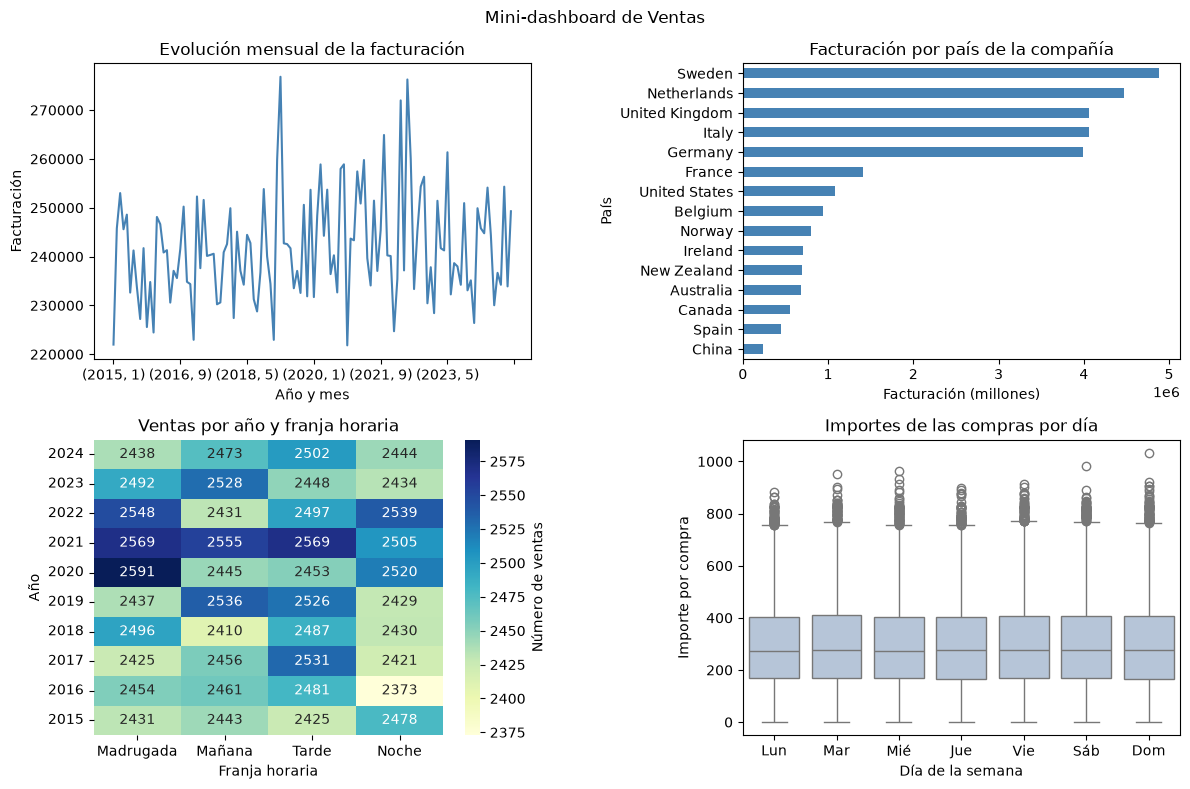

In [107]:
fig, axes = plt.subplots(2,2, figsize=(12,8))

fig.suptitle("Mini-dashboard de Ventas")

ventas_mensuales.plot(
    kind="line",
    ax=axes[0, 0],
    color="steelblue"
)

axes[0, 0].set_title("Evolución mensual de la facturación")
axes[0, 0].set_xlabel("Año y mes")
axes[0, 0].set_ylabel("Facturación")


# 2do gráfico
facturacion_por_pais_ordenada.plot(
    kind="barh",
    ax=axes[0, 1],
    color="steelblue"
)

axes[0, 1].set_title("Facturación por país de la compañía")
axes[0, 1].set_xlabel("Facturación (millones)")
axes[0, 1].set_ylabel("País")
axes[0, 1].invert_yaxis()

# 3er gráfico
sns.heatmap(
    tabla_franjas[["Madrugada", "Mañana", "Tarde", "Noche"]],
    annot= True,
    fmt="d",
    cmap="YlGnBu",
    cbar_kws= {"label": "Número de ventas"},
    ax=axes[1,0]
)

axes[1, 0].set_title("Ventas por año y franja horaria")
axes[1, 0].set_xlabel("Franja horaria")
axes[1, 0].set_ylabel("Año")
axes[1, 0].invert_yaxis()


# 4to gráfico
sns.boxplot(
    data=df_ventas,
    x="dia_transacciones",
    y="amount",
    order=[0,1,2,3,4,5,6],
    color="lightsteelblue",
    ax=axes[1,1]
)

axes[1, 1].set_title("Importes de las compras por día")
axes[1, 1].set_xlabel("Día de la semana")
axes[1, 1].set_ylabel("Importe por compra")
axes[1, 1].set_xticks(
    range(7),
    labels=["Lun", "Mar", "Mié", "Jue", "Vie", "Sáb", "Dom"]
)

plt.tight_layout(w_pad=5)
plt.show()

En el 4to gráfico boxplot veo que los importes de las compras tienen una distribución muy parecida todos los días:

- Las medianas —las líneas dentro de las cajas— están alrededor de 270–280.
- Las cajas tienen una altura similar: el 50 % central de las compras está aproximadamente entre 170 y 400.
- Hay compras de importes especialmente altos todos los días, representadas por los círculos sobre el bigote superior. 
No significa que sean errores.

Para Ventas / Comercial, esto sugiere que no hay un día que destaque claramente por tener compras de mayor importe habitual. Para saber qué días generan más facturación, también habría que considerar cuántas compras se realizan: este boxplot no muestra ese recuento.

**Interpretación conjunta del mini-dashboard**

La facturación mensual presenta subidas y bajadas, sin una tendencia sostenida de crecimiento ni una estacionalidad claramente visible. Por países de las compañías vendedoras, los ingresos se concentran principalmente en Suecia, Países Bajos, Reino Unido, Italia y Alemania.

Las ventas se distribuyen de forma bastante equilibrada entre las cuatro franjas horarias, sin que ninguna destaque de manera constante a lo largo de los años. Además, los importes por compra presentan medianas y una dispersión muy similares entre los días de la semana.

Para el departamento de Ventas / Comercial, estos resultados señalan que conviene vigilar la concentración de ingresos en los principales países vendedores y estudiar cómo aumentar la aportación de los demás. Los patrones horarios y los importes por día no muestran diferencias claras que, por sí solas, justifiquen concentrar las acciones comerciales en un horario o día específico. Antes de decidir, sería útil analizar también el número de compras por día, los márgenes y los resultados de campañas anteriores.

## Ejercicio 2: Informe ejecutivo

🎯 Objetivo: A partir del dashboard, presenta un informe ejecutivo en dos versiones:

- Sin IA.
- Con apoyo de IA.

Sin IA:

Redactado con tus propias palabras.

Con apoyo de IA:

Utilizando herramientas de IA para:
- Mejorar la redacción.
- Adaptar el lenguaje al departamento elegido.
- Incorporar vocabulario técnico de negocio.

El informe debe contener obligatoriamente:

1. Resumen general —máximo 5 líneas—: qué se ha analizado y con qué objetivo.
2. Hallazgos clave —entre 3 y 5—: conclusiones sólidas basadas en datos reales.
3. Riesgos detectados: por ejemplo, dependencia excesiva de productos o empresas, falta de captación de nuevos usuarios, franjas horarias críticas, posibles indicios de fraude o anomalías…
4. Oportunidades: mejoras operativas, segmentos no explotados, productos o franjas con potencial, optimización de recursos…
5. Recomendaciones: acciones concretas y no técnicas, orientadas al negocio.

📌 Clave del nivel 3

No se trata de demostrar que sabes hacer gráficos, sino de demostrar que entiendes los datos y sabes explicar qué hacer con ellos.

- Implementar estrategias comerciales orientadas a la fidelización y a la previsibilidad del volumen de ventas.

### INFORME EJECUTIVO SIN IA:

Departamento de Ventas/Comercial


RESUMEN GENERAL 

Se ha hecho un análisis del comportamiento de ciertas variables, utilizadas en el área de Ventas, para ver evolución mensual de facturación entre los años 2015 y 2024, la facturación por país de la compañía, el comportamiento de las ventas por franja horaria y de los importes de las compras por día de la semana. Todo esto con el objetivo de tomar mejores decisiones comerciales y/o de expansión.

HALLAZGOS CLAVE

* Evolución mensual de facturación: entre los años 2015 y 2024, se puede observar un comportamiento estable, con ciertas subidas y bajadas entre los años 2019 y 2022, pero nada drástico.

* Facturación por país de la compañía: Suecia es el país que concentra la mayor parte de facturación de las compañías vendedoras, seguido de Países Bajos, Reino Unido, Italia y Alemania.

* Ventas por año y franja horaria: Entre los años 2015 y 2024 no existe mucha diferencia en el número de ventas. El mínimo es de 2375 y el máximo es de 2575. En todos ellos, hay altibajos de ventas y no destaca ninguna franja horaria.

* Importes de las compras por día: analizando las compras por día de la semana, tanto sus medianas como su dispersión, son muy parecidas, pero no iguales, ya que en algunos días hay compras puntuales atípicas.


RIESGOS DETECTADOS

* El principal riesgo detectado es la concentración de facturación en los cinco países anteriormente señalados como Suecia, Países Bajos, Reino Unido, Italia y Alemania, ya que acumulan casi el 74% de aquella. Una caída repentina y abrupta en alguno de estos países puede afectar fuertemente a la facturación total.

* Por otro lado, la facturación total de la empresa se ha mantenido estable, con fluctuaciones, durante los años estudiados (2015-2024) pero sin tendencia de crecimiento, lo que podría indicar un riesgo de estancamiento.

OPORTUNIDADES

* Al haber países con menos participación en la facturación total, habría que estudiar la posibilidad de tomar acciones comerciales para que puedan tenerla, y así no depender en mayor cantidad de un solo grupo de países. 

* Dicho lo anterior, también sería una oportunidad el promover accionar comerciales  que la facturación no se llegue a estancar, y pueda tener un crecimiento.

* En cuanto a las franjas horarias, sería bueno estudiar la posibilidad de tomar acciones para cualquiera de ellas y analizar su respuesta para futuras campañas de marketing. 

RECOMENDACIONES

* Realizar estudios de mercado o de comportamiento del consumidor en los países que representan poca facturación.

* De ésta se desprende hacerse la pregunta de si es necesaria la presencia del negocio en dicho país y porqué, y comprobar si es mejor dejarla para otro país.

* Revisar cada cierto tiempo la evolución de la facturación por país y detectar cambios inesperados.

* En cuanto a las franjas horarias, se podría probar campañas en cualquiera de ellas para comparar sus resultados antes de tomar cualquier decisión comercial.

* Investigar lo meses que han tenido picos de facturación, los cuales han sido pocos, para ver si coinciden con alguna promoción especial de temporada o alguna campaña de marketing.

* Promover acciones de fidelización con los clientes recurrentes y en base a ello, investigar cuáles podrían ser para captar nuevos.


INFORME EJECUTIVO CON SOPORTE DE LA IA

RESUMEN GENERAL

Se ha analizado el desempeño comercial entre 2015 y 2024 a partir de cuatro indicadores: evolución mensual de la facturación, facturación por país, volumen de ventas por franja horaria e importe por compra (ticket) según el día de la semana. El objetivo es identificar riesgos y oportunidades que respalden la toma de decisiones comerciales y la estrategia de expansión.

HALLAZGOS CLAVE

* Facturación mensual: comportamiento estable entre 2015 y 2024, con fluctuaciones y picos puntuales entre 2019 y 2022, sin una tendencia clara de crecimiento ni de caída.

* Facturación por país: Suecia lidera el ranking, seguida de Países Bajos, Reino Unido, Italia y Alemania. El resto de mercados aporta una participación comparativamente baja.

* Ventas por franja horaria: volumen muy homogéneo entre años y franjas (entre 2.373 y 2.591 ventas), sin que ninguna franja destaque de forma sostenida.

* Importe por compra: medianas y dispersión muy similares todos los días de la semana, por lo que el día no condiciona el importe del ticket. Solo se observan compras atípicas de alto importe de forma puntual.

RIESGOS DETECTADOS

* Concentración de ingresos: los cinco mercados principales acumulan aproximadamente el 74 % de la facturación. Esta dependencia implica que una caída abrupta en cualquiera de ellos afectaría de forma significativa a los ingresos totales.

* Riesgo de estancamiento: la facturación se mantiene estable, con fluctuaciones, pero sin tendencia de crecimiento. Esto podría indicar una meseta y falta de dinamismo comercial.

OPORTUNIDADES

* Diversificación geográfica: potenciar los mercados de menor participación para reducir la dependencia de los cinco principales.

* Reactivación del crecimiento: impulsar acciones comerciales que permitan salir de la meseta actual.

* Segmentación horaria: al no existir una franja dominante, hay margen para probar campañas por franja y medir su respuesta de cara a futuras acciones de marketing.

RECOMENDACIONES

* Realizar estudios de mercado y de comportamiento del consumidor en los países de baja facturación.

* Fidelización y captación: impulsar acciones de fidelización dirigidas a los clientes recurrentes y, a partir de lo que funcione con ellos, definir qué iniciativas podrían ser eficaces para captar nuevos clientes, con el fin de reactivar el crecimiento de la facturación.

* Evaluar la viabilidad de mantener presencia en los mercados de menor aportación y valorar reasignar recursos hacia mercados con mayor potencial.

* Monitorizar periódicamente la facturación por país para detectar desviaciones inesperadas.

* Pilotar campañas por franja horaria (tipo test A/B) y comparar resultados antes de tomar decisiones comerciales.

* Analizar los meses con picos de facturación, que han sido pocos, para comprobar si coinciden con promociones o campañas estacionales.